In [7]:
import sys 
import os
from datetime import datetime
today = datetime.now().strftime("%Y-%m-%d")

import anndata as ad
import hdf5plugin
import squidpy as sq
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from spatialdata_io.readers.xenium import xenium_aligned_image
import spatialdata as sd
import rapids_singlecell as rsc

import warnings
warnings.filterwarnings('ignore', category=ad.ImplicitModificationWarning)

# Add repo path to sys path (allows to access scripts and metadata from repo)
repo_path,_ = os.path.split(os.path.split(os.getcwd())[0])
repo_path = '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses'
sys.path.insert(1, repo_path) 
sys.path.insert(2, '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/scripts')
sys.path.insert(3, '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts')

# Autoreload custom scripts
%load_ext autoreload
%autoreload 2

# Define paths
plots_path = f'{repo_path}/plots/'
data_path = f'{repo_path}/data/'
model_path = os.path.join(repo_path, 'models')
general_data_path = '/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/data/'

print('Dir for plots: {}'.format(plots_path))
print('Dir for data: {}'.format(data_path))

# Formatting
from matplotlib import font_manager
font_manager.fontManager.addfont("/nfs/team205/ny1/ThymusSpatialAtlas/software/Arial.ttf")
plt.style.use('/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts/plotting/thyAgeing.mplstyle')

from plotting.utils import calc_figsize, thyAgeing_greys, thyAgeing_colors
from anno_levels import get_ct_levels

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Dir for plots: /nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/plots/
Dir for data: /nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/data/


In [8]:
# Load general and HnE metadata
from utils import get_latest_version,update_obs
latest_meta_path = get_latest_version(dir = f'{general_data_path}/metadata', file_prefix='Thymus_ageing_metadata')
latest_meta = pd.read_excel(latest_meta_path)

he_meta = pd.read_csv('/lustre/scratch126/cellgen/teichmann/lm25/data/thymus_he/thyAgeing_HnE.csv')
he_meta = he_meta.merge(latest_meta[['donor', 'sex', 'age_group']].drop_duplicates(), left_on = 'DonorID', right_on = 'donor', how = 'left').drop('donor', axis = 1)
he_meta['SampleID'] = he_meta['file_name'].str.split(' - ').str[0]
he_meta.head()

Latest file: Thymus_ageing_metadata_v30_2026-07-09.xlsx


,file_name,image_id,DonorID,tissue_embedding,resolution,dimensions,n_slices,info_slices,format,annotation_file,has_xenium,source,file_path,sex,age_group,SampleID
0,U48-THY-0-FFPE-1-S7-i_S000005312 - 2025-01-10 ...,75701.0,U48,FFPE,0.227,45056 x 48384,1,NaN,ndpi,NaN,False,CAM,/lustre/scratch126/cellgen/teichmann/lm25/data...,M,infant,U48-THY-0-FFPE-1-S7-i_S000005312
1,U40-THY-0-FFPE-1-S18-i_S000005306 - 2025-01-10...,75698.0,U40,FFPE,0.227,49152 x 35840,1,NaN,ndpi,NaN,False,CAM,/lustre/scratch126/cellgen/teichmann/lm25/data...,F,infant,U40-THY-0-FFPE-1-S18-i_S000005306
2,Z11-THY-0-FFPE-1-S1i_S5297 - 2024-12-19 09.00.52,75347.0,Z11,FFPE,0.227,28672 x 30464,1,NaN,ndpi,NaN,False,CAM,/lustre/scratch126/cellgen/teichmann/lm25/data...,F,infant,Z11-THY-0-FFPE-1-S1i_S5297
3,Z12-THY-0-FFPE-1-S2ii_S5298 - 2024-12-19 09.03.17,75350.0,Z12,FFPE,0.227,20480 x 27904,1,NaN,ndpi,NaN,False,CAM,/lustre/scratch126/cellgen/teichmann/lm25/data...,M,paed,Z12-THY-0-FFPE-1-S2ii_S5298
4,A45-THY-0-FFPE-1 - 2024-10-15 16.55.54,69701.0,A45,FFPE,0.227,61440 x 64000,3,NaN,ndpi,NaN,False,CAM,/lustre/scratch126/cellgen/teichmann/lm25/data...,M,adult,A45-THY-0-FFPE-1


In [3]:
xenium_adata = ad.read_h5ad('/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/xenium_proseg/xenium_aging_labels.h5ad')

# Add cell coordinates
xenium_adata_spatial = ad.read_h5ad('/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/xenium_proseg/xenium_proseg_aging.h5ad', backed = 'r')
xenium_adata.obsm['spatial'] = xenium_adata_spatial.obsm['spatial']

# Add cell annotations
xenium_cellanno = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/ThyAge_xenium_annos_v1-v2_predict_2026-07-15.csv', index_col=0)[['proseg_barcode', 'taa_l2_comb', 'taa_l3_comb', 'niche_cellcharter3_v2_comb', 'niche_cellcharter6_comb']].set_index('proseg_barcode')
xenium_adata.obs[xenium_cellanno.columns] = xenium_cellanno.loc[xenium_adata.obs_names, :]

# Add morpho niche annotations
xenium_morpho = pd.read_csv(f'{data_path}/xenium/thyAging_xenium_morpho_niches.csv', index_col=0)
xenium_morpho = xenium_morpho.reindex(xenium_adata.obs_names)
xenium_adata.obs[xenium_morpho.columns] = xenium_morpho.loc[xenium_adata.obs_names, :]

xenium_adata = xenium_adata[xenium_adata.obs['morpho_niche_keep'] == True]

# Remove donor A45 as failed QC
xenium_adata = xenium_adata[xenium_adata.obs['donor'] != 'A45']

xenium_adata

/tmp/ipykernel_3319876/1382109997.py:8: DtypeWarning: Columns (35,36,37,38) have mixed types. Specify dtype option on import or set low_memory=False.
  xenium_cellanno = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/xenium/ThyAge_xenium_annos_v1-v2_predict_2026-07-15.csv', index_col=0)[['proseg_barcode', 'taa_l2_comb', 'taa_l3_comb', 'niche_cellcharter3_v2_comb', 'niche_cellcharter6_comb']].set_index('proseg_barcode')


View of AnnData object with n_obs × n_vars = 3332902 × 5043
    obs: 'sample_ID', 'donor', 'chemistry_simple', 'cells_spatial', '_scvi_batch', '_scvi_labels', 'X_scVI_shortlist_v1_leiden_1', 'level_0_pred', 'level_0_prob', 'level_1_pred', 'level_1_prob', 'level_2_pred', 'level_2_prob', 'level_3_pred', 'level_3_prob', 'level_4_pred', 'level_4_prob', 'level_5_pred', 'level_5_prob', 'level_2v2_pred', 'level_2v2_prob', 'level_3v2_pred', 'level_3v2_prob', 'taa_l2_comb', 'taa_l3_comb', 'niche_cellcharter3_v2_comb', 'niche_cellcharter6_comb', 'SampleID_he', 'patch_col', 'patch_row', 'patchID', 'leiden_r2.0', 'morpho_niche_l3', 'morpho_niche_l2', 'morpho_niche_l1', 'morpho_niche_keep', 'leiden_r2.0_concat'
    uns: 'X_scVI_shortlist_v1_leiden_1', '_scvi_manager_uuid', '_scvi_uuid', 'cells_spatial_colors', 'log1p', 'neighbors', 'umap'
    obsm: 'X_scVI_shortlist_v1', 'X_umap', '_scvi_extra_categorical_covs', 'spatial'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [4]:
xenium_adata.obs['morpho_niche_l3'] = pd.Categorical(xenium_adata.obs['morpho_niche_l3'], categories=['cortex_septal','cortex_outer','cortex_dense', 'cortex', 'cortex_residual',
                    'medulla', 'medulla_hc', 'medulla_residual', 
                    'adipose', 'adipose_edge',
                    'fibrosis', 'fibrosis_adipose',
                    'endothelium_vessel', 'endothelium_edge',])
xenium_adata.obs['morpho_niche_l2'] = pd.Categorical(xenium_adata.obs['morpho_niche_l2'], categories=['cortex_septal','cortex', 'medulla', 'medulla_hc', 'adipose', 'fibrosis_adipose', 'fibrosis', 'vessel',])

In [5]:
# Check whether taa_l2_comb matches taa_l2_v2
anno_levels = pd.read_excel(f'{general_data_path}/curated/thyAgeing_full_curatedAnno_v11_2025-08-29_levels.xlsx')
assert all([c for c in xenium_adata.obs['taa_l2_comb'].unique() if c not in anno_levels['taa_l2_v2'].unique()]), "Some of the cell annotations in the xenium data are not present in the curated annotation levels. Please check the annotations and update accordingly."

col_cell_type_levels = get_ct_levels('taa_l2_v2')
col_cell_type_levels.remove('DC')
col_cell_type_levels.remove('TEC-EMT')

assert all([c for c in xenium_adata.obs['taa_l3_comb'].unique() if c not in anno_levels['taa_l3_v2'].unique()]), "Some of the cell annotations in the xenium data are not present in the curated annotation levels. Please check the annotations and update accordingly."
col_cell_type_levels_broad = [c for c in get_ct_levels('taa_l3') if c in xenium_adata.obs['taa_l3_comb'].unique()]

print(col_cell_type_levels)
print(col_cell_type_levels_broad)

Latest file: thyAgeing_full_curatedAnno_v11_2025-08-29_levels.xlsx
Latest file: thyAgeing_full_curatedAnno_v11_2025-08-29_levels.xlsx
['T_DN(early)', 'T_DN', 'T_DP', 'T_αβT(entry)', 'T_mature', 'T_recirc', 'T_innate', 'NK', 'cTEC', 'mcTEC', 'mTEC', 'Fb', 'Adipocyte', 'EC-blood', 'EC-lymphatic', 'SMC', 'Pericyte', 'B_cell', 'B_plasma', 'Myeloid_dev', 'Neutrophil', 'Mono', 'Mac', 'DC1', 'DC2', 'aDC', 'pDC', 'Mast']
['T_DN(early)', 'T_DN', 'T_DP', 'T_αβT(entry)', 'T_CD8', 'T_CD4', 'T_Treg', 'T_CD8_recirc', 'T_CD4_recirc', 'T_Treg_recirc', 'T_CD8αα', 'T_MAIT', 'ILC', 'T_γδT', 'NK', 'cTEC', 'mcTEC', 'mTECI', 'mTECII', 'mTECIII', 'TEC-mim', 'TEC-EMT', 'Fb-interlo', 'Fb-perilo', 'Fb-med', 'Fb-interm', 'Fb-adipo', 'Adipocyte', 'EC-art', 'EC-cap', 'EC-cap_lipid', 'EC-ven', 'EC-peri', 'EC-lymphatic', 'SMC', 'Pericyte', 'B_dev', 'B_naive', 'B_mem', 'B_GC-like', 'B_plasma', 'Myeloid_dev', 'Neutrophil', 'Mono', 'Mac', 'DC1', 'DC2', 'aDC', 'pDC', 'Mast']


## Cell composition plots

### Enrichment plots

In [6]:
# Remove donor A45 as failed QC
xenium_adata = xenium_adata[xenium_adata.obs['donor'] != 'A45']
xenium_adata.shape

(3317869, 5043)

In [6]:
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

def cluster_enrichment(obs, leiden_col, anno_col, donor_col='DonorID', pseudocount=0.1):
    """
    Per-donor log2 observed/expected enrichment of each cell type in each cluster,
    aggregated across donors with a one-sample t-test (H0: log2 O/E = 0).
    O/E normalises out cluster size AND global cell-type abundance, so it is not
    dominated by abundant populations (e.g. DP thymocytes).
    """
    recs = []
    for donor, g in obs.groupby(donor_col, observed=True):
        ct = pd.crosstab(g[leiden_col], g[anno_col])
        N   = ct.values.sum()
        row = ct.sum(1).values[:, None]     # cells per cluster
        col = ct.sum(0).values[None, :]     # cells per cell type
        expected = row @ col / N
        log2oe = np.log2((ct.values + pseudocount) / (expected + pseudocount))
        tmp = pd.DataFrame(log2oe, index=ct.index, columns=ct.columns)
        tmp = tmp.reset_index().melt(id_vars=leiden_col, var_name=anno_col,
                                     value_name='log2oe')
        tmp[donor_col] = donor
        recs.append(tmp)
    long = pd.concat(recs, ignore_index=True)

    def agg(s):
        s = s.dropna()
        t, p = (stats.ttest_1samp(s, 0.0) if len(s) > 1 and s.std() > 0
                else (np.nan, np.nan))
        return pd.Series({'mean_log2oe': s.mean(), 'std_log2oe': s.std(ddof=1),
                          'n_donors': len(s), 't': t, 'pval': p})

    summary = (long.groupby([leiden_col, anno_col], observed=True)['log2oe']
                   .apply(agg).unstack().reset_index())
    m = summary['pval'].notna()
    summary.loc[m, 'padj'] = multipletests(summary.loc[m, 'pval'], method='fdr_bh')[1]
    return summary, long


In [ ]:
from plotting.utils import create_diverging_palette

# Perform cluster enrichment analysis for xenium data
cell_anno_col = 'taa_l2_comb'
niche_anno_col = 'morpho_niche_l2'
patch_summary = xenium_adata.obs[['donor','patchID', cell_anno_col, niche_anno_col]].copy()
summary, long = cluster_enrichment(patch_summary, niche_anno_col, cell_anno_col, donor_col='donor')
summary[cell_anno_col] = pd.Categorical(summary[cell_anno_col], categories=col_cell_type_levels, ordered=True)

plot_df = summary.pivot(index=niche_anno_col, columns=cell_anno_col, values='mean_log2oe')

# Order axes if categorical
if hasattr(summary[niche_anno_col], 'cat'):
    plot_df = plot_df.reindex(index=summary[niche_anno_col].cat.categories[::-1])
if hasattr(summary[cell_anno_col], 'cat'):
    plot_df = plot_df.reindex(columns=summary[cell_anno_col].cat.categories)
    
#plot_df = plot_df.loc[~plot_df.index.str.contains('artifact')]
plot_df.fillna(0, inplace=True)

cmap = create_diverging_palette(thyAgeing_colors['teal'], thyAgeing_colors['orange'], s = 90, l = 60, as_cmap = True)

vmax = 3
fig, ax = plt.subplots(figsize=calc_figsize(width=220, height=plot_df.shape[0]*5))
g = sns.clustermap(
    plot_df,
    cmap=cmap,
    center=0,
    vmin=-vmax,
    vmax=vmax,
    figsize=calc_figsize(width=180, height=plot_df.shape[0]*7), #calc_figsize(height=30, width=180)
    cbar_kws={'label': 'mean_log2oe'},
    row_cluster=False,
    col_cluster=False,
    #dendrogram_ratio=(0.06, 0.06),   # reduce dendrogram -> heatmap gap
    cbar_pos=(0.02, 0.75, 0.03, 0.18),
    tree_kws={'linewidth': 0.5},
    xticklabels=True,
    yticklabels=True,
)
ax = g.ax_heatmap
plt.setp(ax.get_xticklabels(), fontsize=8)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=8)
ax.set_xlabel(cell_anno_col)
ax.set_ylabel(niche_anno_col)
#plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/plotting/thyAging_morphoFM_patch_{niche_anno_col}_{cell_anno_col}_log2oe_clustermap.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
from plotting.utils import create_diverging_palette

# Perform cluster enrichment analysis for xenium data
cell_anno_col = 'taa_l2_comb'
niche_anno_col = 'morpho_niche_l2'
patch_summary = xenium_adata.obs[['donor','patchID', cell_anno_col, niche_anno_col]].copy()
summary, long = cluster_enrichment(patch_summary, niche_anno_col, cell_anno_col, donor_col='donor')
summary[cell_anno_col] = pd.Categorical(summary[cell_anno_col], categories=col_cell_type_levels, ordered=True)

plot_df = summary.pivot(index=niche_anno_col, columns=cell_anno_col, values='mean_log2oe')

# Order axes if categorical
if hasattr(summary[niche_anno_col], 'cat'):
    plot_df = plot_df.reindex(index=summary[niche_anno_col].cat.categories[::-1])
if hasattr(summary[cell_anno_col], 'cat'):
    plot_df = plot_df.reindex(columns=summary[cell_anno_col].cat.categories)
    
#plot_df = plot_df.loc[~plot_df.index.str.contains('artifact')]
plot_df.fillna(0, inplace=True)
plot_df.values[plot_df.values < 0] = 0

cmap = sns.blend_palette([thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'], thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True,)

vmax = 2.5
fig, ax = plt.subplots(figsize=calc_figsize(width=220, height=plot_df.shape[0]*5))
g = sns.clustermap(
    plot_df,
    cmap=cmap,
    vmax = vmax,
    figsize=calc_figsize(width=180, height=plot_df.shape[0]*7), #calc_figsize(height=30, width=180)
    cbar_kws={'label': 'mean_log2oe'},
    row_cluster=False,
    col_cluster=False,
    #dendrogram_ratio=(0.06, 0.06),   # reduce dendrogram -> heatmap gap
    cbar_pos=(0.02, 0.75, 0.03, 0.18),
    tree_kws={'linewidth': 0.5},
    xticklabels=True,
    yticklabels=True,
)
ax = g.ax_heatmap
plt.setp(ax.get_xticklabels(), fontsize=8)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=8)
ax.set_xlabel(cell_anno_col)
ax.set_ylabel(niche_anno_col)
#plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/plotting/thyAging_morphoFM_patch_{niche_anno_col}_{cell_anno_col}_log2oe_clustermap_0plus.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
from plotting.utils import create_diverging_palette

# Perform cluster enrichment analysis for xenium data
cell_anno_col = 'taa_l3_comb'
niche_anno_col = 'morpho_niche_l3'
patch_summary = xenium_adata.obs[['donor','patchID', cell_anno_col, niche_anno_col]].copy()
summary, long = cluster_enrichment(patch_summary, niche_anno_col, cell_anno_col, donor_col='donor')
summary[cell_anno_col] = pd.Categorical(summary[cell_anno_col], categories=col_cell_type_levels_broad, ordered=True)

plot_df = summary.pivot(index=niche_anno_col, columns=cell_anno_col, values='mean_log2oe')

# Order axes if categorical
if hasattr(summary[niche_anno_col], 'cat'):
    plot_df = plot_df.reindex(index=summary[niche_anno_col].cat.categories[::-1])
if hasattr(summary[cell_anno_col], 'cat'):
    plot_df = plot_df.reindex(columns=summary[cell_anno_col].cat.categories)
    
#plot_df = plot_df.loc[~plot_df.index.str.contains('artifact')]
plot_df.fillna(0, inplace=True)
plot_df.values[plot_df.values < 0] = 0

plot_df = plot_df.div(plot_df.max(axis=0), axis=1)  # min-max normalization per cell type

cmap = sns.blend_palette([thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'], thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True,)

fig, ax = plt.subplots(figsize=calc_figsize(width=220, height=plot_df.shape[0]*5))
g = sns.clustermap(
    plot_df,
    cmap=cmap,
    figsize=calc_figsize(width=180, height=plot_df.shape[0]*7), #calc_figsize(height=30, width=180)
    cbar_kws={'label': 'mean_log2oe'},
    row_cluster=False,
    col_cluster=False,
    #dendrogram_ratio=(0.06, 0.06),   # reduce dendrogram -> heatmap gap
    cbar_pos=(0.02, 0.75, 0.03, 0.18),
    tree_kws={'linewidth': 0.5},
    xticklabels=True,
    yticklabels=True,
)
ax = g.ax_heatmap
plt.setp(ax.get_xticklabels(), fontsize=8)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=8)
ax.set_xlabel(cell_anno_col)
ax.set_ylabel(niche_anno_col)
#plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/plotting/thyAging_morphoFM_patch_{niche_anno_col}_{cell_anno_col}_log2oe_clustermap_0plus_minmax.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
from plotting.utils import create_diverging_palette
from matplotlib.backends.backend_pdf import PdfPages

age_group_dict = {'infant' : 'U', 'paed' : 'Z', 'adult' : 'A'}

# Perform cluster enrichment analysis for xenium data
cell_anno_col = 'taa_l2_comb'
niche_anno_col = 'morpho_niche_l2'


with PdfPages(f'{plots_path}/morpho_niches2/plotting/thyAging_morphoFM_patch_{niche_anno_col}_{cell_anno_col}_log2oe_clustermap_0plus_minmax_perAgeGroup.pdf') as pdf:
    for age_group in age_group_dict.keys():
        patch_summary = xenium_adata[xenium_adata.obs['donor'].str.startswith(age_group_dict[age_group])].obs[['donor','patchID', cell_anno_col, niche_anno_col]].copy()
        summary, long = cluster_enrichment(patch_summary, niche_anno_col, cell_anno_col, donor_col='donor')
        summary[cell_anno_col] = pd.Categorical(summary[cell_anno_col], categories=col_cell_type_levels, ordered=True)

        plot_df = summary.pivot(index=niche_anno_col, columns=cell_anno_col, values='mean_log2oe')

        # Order axes if categorical
        if hasattr(summary[niche_anno_col], 'cat'):
            plot_df = plot_df.reindex(index=summary[niche_anno_col].cat.categories[::-1])
        if hasattr(summary[cell_anno_col], 'cat'):
            plot_df = plot_df.reindex(columns=summary[cell_anno_col].cat.categories)
            
        #plot_df = plot_df.loc[~plot_df.index.str.contains('artifact')]
        plot_df.fillna(0, inplace=True)
        plot_df.values[plot_df.values < 0] = 0

        plot_df = plot_df.div(plot_df.max(axis=0), axis=1)  # min-max normalization per cell type

        cmap = sns.blend_palette([thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'], thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True,)

        fig, ax = plt.subplots(figsize=calc_figsize(width=220, height=plot_df.shape[0]*5))
        g = sns.clustermap(
            plot_df,
            cmap=cmap,
            figsize=calc_figsize(width=100, height=plot_df.shape[0]*5), #calc_figsize(height=30, width=180)
            cbar_kws={'label': 'mean_log2oe'},
            row_cluster=False,
            col_cluster=False,
            #dendrogram_ratio=(0.06, 0.06),   # reduce dendrogram -> heatmap gap
            cbar_pos=(0.02, 0.75, 0.03, 0.18),
            tree_kws={'linewidth': 0.5},
            xticklabels=True,
            yticklabels=True,
        )
        ax = g.ax_heatmap
        plt.setp(ax.get_xticklabels(), fontsize=5)
        plt.setp(ax.get_yticklabels(), rotation=0, fontsize=5)
        ax.set_xlabel(cell_anno_col)
        ax.set_ylabel(niche_anno_col)
        ax.set_title(f'Age group: {age_group}')
        pdf.savefig()
        plt.close()

In [15]:
summary

,taa_l2_comb,mean_log2oe
morpho_niche_l2,,
cortex_septal,Adipocyte,2.585086
cortex,Adipocyte,-2.918623
medulla,Adipocyte,-1.436036
medulla_hc,Adipocyte,-0.536383
adipose,Adipocyte,4.039355
...,...,...
medulla_hc,pDC,1.831408
adipose,pDC,-0.278204
fibrosis_adipose,pDC,-3.286892


In [22]:
counts.max(axis = 0)

taa_l2_comb
Adipocyte         3605
B_cell           74410
B_plasma         16603
DC1               4667
DC2               2756
EC-blood         21658
EC-lymphatic       871
Fb               18941
Mac              16639
Mast              3209
Mono              1442
Myeloid_dev        558
NK                  92
Neutrophil         246
Pericyte          3881
SMC               6319
T_DN              2944
T_DN(early)         51
T_DP            185051
T_innate         11298
T_mature         55327
T_recirc         88810
T_αβT(entry)     31555
aDC               4007
cTEC              6587
mTEC             34675
mcTEC            52014
pDC               1250
dtype: int64

In [25]:
plot_df

taa_l2_comb,Adipocyte,B_cell,B_plasma,DC1,DC2,EC-blood,EC-lymphatic,Fb,Mac,Mast,...,T_DP,T_innate,T_mature,T_recirc,T_αβT(entry),aDC,cTEC,mTEC,mcTEC,pDC
morpho_niche_l2,,,,,,,,,,,,,,,,,,,,,
cortex_septal,-1.165020,-0.907541,-0.538878,-0.356912,-0.142604,0.107081,-1.559328,0.285469,0.552497,0.528543,...,-0.391324,0.243062,-0.274687,-0.293046,-0.164921,-2.041877,0.788865,-0.962869,1.478932,-1.001908
cortex,-1.673931,-1.942628,-2.678623,-0.938103,-1.210777,-2.280235,-2.636052,-2.350921,-0.807894,-1.349812,...,1.176046,-0.386174,-0.446315,-1.193669,0.645162,-1.742279,0.667368,-2.029535,-1.370666,-0.733281
medulla,-1.676937,0.562029,-0.338495,0.380782,0.311031,-0.333252,-1.742477,-0.384499,-0.039108,-0.016736,...,-0.543955,0.216754,0.325382,0.400753,-0.085589,0.596046,-0.263464,0.464630,0.155322,0.478230
medulla_hc,-5.206859,0.138658,-2.751401,0.423327,0.542609,-2.331052,-5.152158,-2.314654,0.301704,-2.025497,...,-2.577467,0.672736,0.684609,0.434770,0.106634,0.724547,0.798970,2.551178,0.251467,-0.848725
adipose,2.867262,-0.083938,1.485002,-0.534632,-0.803489,1.633214,0.859792,1.571045,0.502645,0.692625,...,-1.686678,-0.400954,-0.554502,-0.120711,-1.123296,-2.074612,-2.133384,-2.168910,-0.237075,-1.037926
fibrosis_adipose,1.963400,-0.236128,0.545788,-0.469901,0.125614,0.465193,1.664923,1.465682,0.386009,0.650243,...,-0.377133,-0.081372,-0.457220,-0.083516,-0.489285,0.222404,-0.987777,-0.050713,-0.390900,0.048974
fibrosis,0.576231,-0.405182,0.307685,0.047156,0.028573,0.384046,1.607824,0.924998,0.351001,0.514946,...,-0.004106,-0.389678,-0.315214,-0.196085,-0.242591,-0.037403,-0.049769,-0.503263,-0.107260,-0.178836
vessel,0.123424,0.052646,1.597691,0.087925,0.602426,1.201382,2.492262,1.064841,0.358755,0.817116,...,-1.250888,-0.391431,-0.435894,0.012012,-1.126477,0.351908,-2.184268,-0.894554,-0.460231,0.152070


In [27]:
summary['taa_l2_comb'].cat.categories

Index(['T_DN(early)', 'T_DN', 'T_DP', 'T_αβT(entry)', 'T_mature', 'T_recirc',
       'T_innate', 'NK', 'cTEC', 'mcTEC', 'mTEC', 'Fb', 'Adipocyte',
       'EC-blood', 'EC-lymphatic', 'SMC', 'Pericyte', 'B_cell', 'B_plasma',
       'Myeloid_dev', 'Neutrophil', 'Mono', 'Mac', 'DC1', 'DC2', 'aDC', 'pDC',
       'Mast'],
      dtype='object')

In [30]:
plot_df = plot_df.reindex(index=summary[niche_anno_col].cat.categories[::-1])
plot_df = plot_df.reindex(columns=summary[cell_anno_col].cat.categories)

plot_df

,T_DN(early),T_DN,T_DP,T_αβT(entry),T_mature,T_recirc,T_innate,NK,cTEC,mcTEC,...,B_plasma,Myeloid_dev,Neutrophil,Mono,Mac,DC1,DC2,aDC,pDC,Mast
vessel,-1.436104,-1.161704,-1.250888,-1.126477,-0.435894,0.012012,-0.391431,0.656139,-2.184268,-0.460231,...,1.597691,0.489869,-0.094406,0.959834,0.358755,0.087925,0.602426,0.351908,0.152070,0.817116
fibrosis,-0.191724,-0.022030,-0.004106,-0.242591,-0.315214,-0.196085,-0.389678,0.514881,-0.049769,-0.107260,...,0.307685,-0.041858,-0.931768,1.191756,0.351001,0.047156,0.028573,-0.037403,-0.178836,0.514946
fibrosis_adipose,-0.088684,-0.354650,-0.377133,-0.489285,-0.457220,-0.083516,-0.081372,0.031006,-0.987777,-0.390900,...,0.545788,0.039281,0.319462,0.673140,0.386009,-0.469901,0.125614,0.222404,0.048974,0.650243
adipose,-0.448534,-1.289909,-1.686678,-1.123296,-0.554502,-0.120711,-0.400954,0.911758,-2.133384,-0.237075,...,1.485002,1.111469,1.536030,0.802781,0.502645,-0.534632,-0.803489,-2.074612,-1.037926,0.692625
medulla_hc,-0.361361,-1.425434,-2.577467,0.106634,0.684609,0.434770,0.672736,-2.341874,0.798970,0.251467,...,-2.751401,0.037821,0.249576,-0.162795,0.301704,0.423327,0.542609,0.724547,-0.848725,-2.025497
medulla,-0.146956,-0.325132,-0.543955,-0.085589,0.325382,0.400753,0.216754,-0.126605,-0.263464,0.155322,...,-0.338495,-0.331952,-0.208900,-0.422291,-0.039108,0.380782,0.311031,0.596046,0.478230,-0.016736
cortex,0.329359,0.806791,1.176046,0.645162,-0.446315,-1.193669,-0.386174,-0.569174,0.667368,-1.370666,...,-2.678623,-1.737863,-1.735288,-1.162363,-0.807894,-0.938103,-1.210777,-1.742279,-0.733281,-1.349812
cortex_septal,1.039082,0.580393,-0.391324,-0.164921,-0.274687,-0.293046,0.243062,0.001645,0.788865,1.478932,...,-0.538878,1.477453,1.178339,0.743732,0.552497,-0.356912,-0.142604,-2.041877,-1.001908,0.528543


In [ ]:
from plotting.utils import create_diverging_palette
from matplotlib.backends.backend_pdf import PdfPages

age_group_dict = {'infant' : 'U', 'paed' : 'Z', 'adult' : 'A'}

# Perform cluster enrichment analysis for xenium data
cell_anno_col = 'taa_l2_comb'
niche_anno_col = 'morpho_niche_l2'

def group_enrichment(obs, cluster_col, anno_col, pseudocount=0.5, min_cells=10):
    ct = pd.crosstab(obs[cluster_col], obs[anno_col])          # one pooled table
    ct = ct.loc[:, ct.sum(0) >= min_cells]                     # drop ultra-rare types
    N   = ct.values.sum()
    exp = ct.sum(1).values[:, None] @ ct.sum(0).values[None, :] / N
    log2oe = np.log2((ct.values + pseudocount) / (exp + pseudocount))
    return pd.DataFrame(log2oe, index=ct.index, columns=ct.columns)

def enrichment_dotplot(plot_df, count_df, ax, cmap, vmax=3, size_max=250,
                       size='colprop', min_size=4):
    """
    Dot color = mean_log2oe (diverging, centred at 0); dot size = support.
      size='colprop': fraction of each cell type's cells that fall in the niche
                      (column-normalised -> sums to 1 down each cell-type column).
      size='count'  : log10 cell count.
    """
    count_df = count_df.reindex(index=plot_df.index, columns=plot_df.columns).fillna(0)
    ny, nx = plot_df.shape
    X, Y = np.meshgrid(np.arange(nx), np.arange(ny))
    vals = plot_df.values.ravel()
    C = count_df.values.astype(float)

    if size == 'colprop':
        col_tot = C.sum(0, keepdims=True)
        frac = np.divide(C, col_tot, out=np.zeros_like(C), where=col_tot > 0)
        sizes = frac.ravel() * size_max               # area ∝ proportion (0..1)
    else:
        denom = np.log10(C.max() + 1) or 1
        sizes = np.log10(C.ravel() + 1) / denom * size_max

    sizes = np.where(sizes > 0, np.maximum(sizes, min_size), 0)  # keep tiny-but-present visible

    sc = ax.scatter(X.ravel(), Y.ravel(), c=vals, s=sizes, cmap=cmap,
                    vmin=-vmax, vmax=vmax, edgecolor='0.5', linewidth=0.2)
    ax.set_xticks(range(nx)); ax.set_xticklabels(plot_df.columns, rotation=90, fontsize=5)
    ax.set_yticks(range(ny)); ax.set_yticklabels(plot_df.index, fontsize=5)
    ax.set_xlim(-0.5, nx-0.5); ax.set_ylim(-0.5, ny-0.5)
    ax.invert_yaxis()
    return sc


with PdfPages(f'{plots_path}/morpho_niches2/plotting/thyAging_morphoFM_patch_{niche_anno_col}_{cell_anno_col}_log2oe_clustermap_perAgeGroup.pdf') as pdf:
    for age_group in age_group_dict.keys():
        patch_summary = xenium_adata[xenium_adata.obs['donor'].str.startswith(age_group_dict[age_group])].obs[['donor','patchID', cell_anno_col, niche_anno_col]].copy()
        
        # LogOE enrichment
        summary = group_enrichment(patch_summary, niche_anno_col, cell_anno_col).melt(ignore_index=False, var_name=cell_anno_col, value_name='mean_log2oe').reset_index(names=niche_anno_col)
        summary[cell_anno_col] = pd.Categorical(summary[cell_anno_col], categories=col_cell_type_levels, ordered=True)
        plot_df = summary.pivot(index=niche_anno_col, columns=cell_anno_col, values='mean_log2oe')

        # Order axes if categorical
        plot_df = plot_df.reindex(index=summary[niche_anno_col].cat.categories[::-1])
        plot_df = plot_df.reindex(columns=summary[cell_anno_col].cat.categories)
            
        #plot_df = plot_df.loc[~plot_df.index.str.contains('artifact')]
        plot_df.fillna(0, inplace=True)
        
        # Filter out niches and cell types with too few cells
        counts = pd.crosstab(patch_summary[niche_anno_col], patch_summary[cell_anno_col])  # cells per (niche, celltype)
        counts  = counts.reindex(index=plot_df.index, columns=plot_df.columns).fillna(0)
        # min_niche_cells, min_celltype_cells = 200, 50

        # keep_niche = counts.sum(1) >= min_niche_cells
        # keep_cell  = counts.sum(0) >= min_celltype_cells
        # plot_df = plot_df.loc[keep_niche[keep_niche].index, keep_cell[keep_cell].index]

        cmap = create_diverging_palette(thyAgeing_colors['teal'], thyAgeing_colors['orange'], s = 90, l = 60, as_cmap = True)

        vmax = 3
        fig, ax = plt.subplots(figsize=calc_figsize(width=120, height=plot_df.shape[0]*6))
        sc = enrichment_dotplot(plot_df, counts, ax, cmap, vmax=vmax)
        cb = fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.02, label='mean_log2oe')
        # size legend
        for c in [50, 500, 5000]:
            ax.scatter([], [], s=np.log10(c+1)/ (np.log10(counts.values.max()+1) or 1)*100,
                    c='grey', edgecolor='0.5', label=f'{c} cells')
        ax.legend(title='n cells', bbox_to_anchor=(1.15, 2), fontsize=5, labelspacing=1.2, frameon=False)
        ax.set_title(f'Age group: {age_group}')
        fig.tight_layout(); pdf.savefig(fig); plt.close(fig)

/tmp/ipykernel_3316807/2446608583.py:72: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(); pdf.savefig(fig); plt.close(fig)
/tmp/ipykernel_3316807/2446608583.py:72: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(); pdf.savefig(fig); plt.close(fig)
/tmp/ipykernel_3316807/2446608583.py:72: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(); pdf.savefig(fig); plt.close(fig)
2026-07-31 09:24:37 | [INFO] maxp pruned
2026-07-31 09:24:37 | [INFO] LTSH dropped
2026-07-31 09:24:37 | [INFO] cmap pruned
2026-07-31 09:24:37 | [INFO] kern pruned
2026-07-31 09:24:37 | [INFO] post pruned
2026-07-31 09:24:37 | [INFO] PCLT dropped
2026-07-31 09:24:37 | [INFO] JSTF dropped
2026-07-31 09:24:37 | [INFO] 

### Plot niche composition by age group

In [7]:
from matplotlib.backends.backend_pdf import PdfPages

def group_enrichment(obs, cluster_col, anno_col, pseudocount=0.5, min_cells=10):
    ct = pd.crosstab(obs[cluster_col], obs[anno_col])          # one pooled table
    ct = ct.loc[:, ct.sum(0) >= min_cells]                     # drop ultra-rare types
    N   = ct.values.sum()
    exp = ct.sum(1).values[:, None] @ ct.sum(0).values[None, :] / N
    log2oe = np.log2((ct.values + pseudocount) / (exp + pseudocount))
    return pd.DataFrame(log2oe, index=ct.index, columns=ct.columns)

def enrichment_dotplot(plot_df, count_df, ax, cmap, vmax=3, size_max=250, vmin = -3,
                       size='rowprop', min_size=4):
    """
    Dot color = mean_log2oe (diverging, centred at 0); dot size = support.
      size='rowprop': fraction of each NICHE's cells that are this cell type
                      (row-normalised -> sums to 1 across each niche row).
      size='colprop': fraction of each cell type's cells in this niche.
      size='count'  : log10 cell count.
    """
    count_df = count_df.reindex(index=plot_df.index, columns=plot_df.columns).fillna(0)
    ny, nx = plot_df.shape
    X, Y = np.meshgrid(np.arange(nx), np.arange(ny))
    vals = plot_df.values.ravel()
    C = count_df.values.astype(float)

    if size == 'rowprop':
        tot = C.sum(1, keepdims=True)
        sizes = np.divide(C, tot, out=np.zeros_like(C), where=tot > 0).ravel() * size_max
    elif size == 'colprop':
        tot = C.sum(0, keepdims=True)
        sizes = np.divide(C, tot, out=np.zeros_like(C), where=tot > 0).ravel() * size_max
    else:
        denom = np.log10(C.max() + 1) or 1
        sizes = np.log10(C.ravel() + 1) / denom * size_max

    sizes = np.where(sizes > 0, np.maximum(sizes, min_size), 0)
    sc = ax.scatter(X.ravel(), Y.ravel(), c=vals, s=sizes, cmap=cmap,
                    vmin=vmin, vmax=vmax, edgecolor='0.5', linewidth=0)
    ax.set_xticks(range(nx)); ax.set_xticklabels(plot_df.columns, rotation=90, fontsize=5)
    ax.set_yticks(range(ny)); ax.set_yticklabels(plot_df.index, fontsize=5)
    ax.set_xlim(-0.5, nx-0.5); ax.set_ylim(-0.5, ny-0.5)
    ax.invert_yaxis()
    return sc

In [ ]:


age_group_dict = {'infant' : 'U', 'paed' : 'Z', 'adult' : 'A'}

# Perform cluster enrichment analysis for xenium data
cell_anno_col = 'taa_l2_comb'
niche_anno_col = 'morpho_niche_l2'


with PdfPages(f'{plots_path}/morpho_niches2/plotting/thyAging_morphoFM_patch_{niche_anno_col}_{cell_anno_col}_log2oe_clustermap_0plus_minmax_perAgeGroup.pdf') as pdf:
    for age_group in age_group_dict.keys():

        patch_summary = xenium_adata[xenium_adata.obs['donor'].str.startswith(age_group_dict[age_group])].obs[['donor','patchID', cell_anno_col, niche_anno_col]].copy()
                
        # LogOE enrichment
        summary = group_enrichment(patch_summary, niche_anno_col, cell_anno_col).melt(ignore_index=False, var_name=cell_anno_col, value_name='mean_log2oe').reset_index(names=niche_anno_col)
        summary[cell_anno_col] = pd.Categorical(summary[cell_anno_col], categories=col_cell_type_levels, ordered=True)
        plot_df = summary.pivot(index=niche_anno_col, columns=cell_anno_col, values='mean_log2oe')

        # Order axes 
        plot_df = plot_df.reindex(index=summary[niche_anno_col].cat.categories[::-1])
        plot_df = plot_df.reindex(columns=summary[cell_anno_col].cat.categories)
        plot_df.fillna(0, inplace=True)

        # Cell counts per niche
        counts = pd.crosstab(patch_summary[niche_anno_col], patch_summary[cell_anno_col])  # cells per (niche, celltype)
        counts  = counts.reindex(index=plot_df.index, columns=plot_df.columns).fillna(0)

        # Per-niche stats from the FULL (pre-filter) patch_summary, aligned to the plotted niches
        cells_per_niche   = patch_summary.groupby(niche_anno_col, observed=True).size().reindex(plot_df.index).fillna(0)
        patches_per_niche = (patch_summary.groupby(niche_anno_col, observed=True)['patchID']
                            .nunique().reindex(plot_df.index).fillna(0))

        ny = plot_df.shape[0]
        fig = plt.figure(figsize=calc_figsize(width=200, height=ny*6))
        gs  = fig.add_gridspec(1, 3, width_ratios=[6, 1, 1], wspace=0.06)
        ax0 = fig.add_subplot(gs[0])
        ax1 = fig.add_subplot(gs[1], sharey=ax0)
        ax2 = fig.add_subplot(gs[2], sharey=ax0)

        # # Enrichment plot (logOE)
        # cmap = create_diverging_palette(thyAgeing_colors['teal'], thyAgeing_colors['orange'], s = 90, l = 60, as_cmap = True)
        # sc = enrichment_dotplot(plot_df, counts, ax0, cmap, vmax=3, vmin =-3, size='rowprop')

        # Enrichment plot (logOE, min-max)
        plot_df.fillna(0, inplace=True)
        plot_df.values[plot_df.values < 0] = 0
        plot_df = plot_df.div(plot_df.max(axis=0), axis=1)  # min-max normalization per cell type
        cmap = sns.blend_palette([thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'], thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True,)
        sc = enrichment_dotplot(plot_df, counts, ax0, cmap, vmax=1, vmin=0, size='colprop')

        # Bar plots for # patches and # cells per niche
        y = np.arange(ny)
        ax1.barh(y, patches_per_niche.values, color='0.6', height=0.7)
        ax2.barh(y, cells_per_niche.values,   color='0.6', height=0.7)
        for a, title, vals in [(ax1, '# patches', patches_per_niche), (ax2, '# cells', cells_per_niche)]:
            a.set_xscale('log')
            a.set_xlim(1, max(vals.max() * 1.5, 10))   # left floor at 1; bars grow rightward
            a.set_title(title, fontsize=6)
            a.tick_params(labelleft=False, labelsize=5)
            for s in ('top', 'right'):
                a.spines[s].set_visible(False)

        # color legend + dot-size legend
        # sc = enrichment_dotplot(plot_df, counts, ax, cmap, vmax=vmax)
        # cb = fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.02, label='mean_log2oe')
        # # size legend
        # for c in [50, 500, 5000]:
        #     ax.scatter([], [], s=np.log10(c+1)/ (np.log10(counts.values.max()+1) or 1)*100,
        #             c='grey', edgecolor='0.5', label=f'{c} cells')
        # ax.legend(title='n cells', bbox_to_anchor=(1.15, 2), fontsize=5, labelspacing=1.2, frameon=False)
        fig.colorbar(sc, ax=ax2, fraction=0.04, pad=0.15, label='mean_log2oe')
        for f in [0.1, 0.25, 0.5, 1.0]:
            ax0.scatter([], [], s=f*250, c='grey', edgecolor='0.5', label=f'{f:.0%}')
        ax0.legend(title="% of niche's\ncells", bbox_to_anchor=(1.55, 1), loc='upper right',
                fontsize=5, labelspacing=1.4, frameon=False)

        ax0.set_xlabel(cell_anno_col); ax0.set_ylabel(niche_anno_col)
        fig.suptitle(f'Age group: {age_group}', fontsize=8)
        fig.tight_layout(); pdf.savefig(fig); plt.close(fig)

Different options for simplified heatmap:

In [22]:
from matplotlib.backends.backend_pdf import PdfPages
from plotting.utils import create_diverging_palette

def group_enrichment(obs, cluster_col, anno_col, pseudocount=0.5, min_cells=10):
    ct = pd.crosstab(obs[cluster_col], obs[anno_col])          # one pooled table
    ct = ct.loc[:, ct.sum(0) >= min_cells]                     # drop ultra-rare types
    N   = ct.values.sum()
    exp = ct.sum(1).values[:, None] @ ct.sum(0).values[None, :] / N
    log2oe = np.log2((ct.values + pseudocount) / (exp + pseudocount))
    return pd.DataFrame(log2oe, index=ct.index, columns=ct.columns)

age_group_dict = {'infant' : 'U', 'paed' : 'Z', 'adult' : 'A'}

# Perform cluster enrichment analysis for xenium data
cell_anno_col = 'taa_l2_comb'
niche_anno_col = 'morpho_niche_l2'

mode = 'log2oe_pos'
min_max = False

mode_name = mode if not min_max else f'{mode}_minmax'

with PdfPages(f'{plots_path}/morpho_niches2/plotting/thyAging_morphoFM_patch_{niche_anno_col}_{cell_anno_col}_{mode_name}_heatmap_perAgeGroup.pdf') as pdf:
    for age_group in age_group_dict.keys():

        patch_summary = xenium_adata[xenium_adata.obs['donor'].str.startswith(age_group_dict[age_group])].obs[['donor','patchID', cell_anno_col, niche_anno_col]].copy()
                
        # LogOE enrichment
        summary = group_enrichment(patch_summary, niche_anno_col, cell_anno_col).melt(ignore_index=False, var_name=cell_anno_col, value_name='mean_log2oe').reset_index(names=niche_anno_col)
        summary[cell_anno_col] = pd.Categorical(summary[cell_anno_col], categories=col_cell_type_levels, ordered=True)
        plot_df = summary.pivot(index=niche_anno_col, columns=cell_anno_col, values='mean_log2oe')

        # Order axes 
        plot_df = plot_df.reindex(index=summary[niche_anno_col].cat.categories[::-1])
        plot_df = plot_df.reindex(columns=summary[cell_anno_col].cat.categories)
        plot_df.fillna(0, inplace=True)

        # Cell counts per niche
        counts = pd.crosstab(patch_summary[niche_anno_col], patch_summary[cell_anno_col])  # cells per (niche, celltype)
        counts  = counts.reindex(index=plot_df.index, columns=plot_df.columns).fillna(0)
        
        if mode == 'colprop':
            counts = counts.div(counts.sum(axis=0), axis=1)  # column-normalized -> sums to 1 down each cell-type column
            
            if min_max:
                        counts = counts.div(counts.max(axis=0), axis=1)  # min-max normalization per cell type
                        
        if mode == 'rowprop':
            counts = counts.div(counts.sum(axis=1), axis=0)  # row-normalized -> sums to 1 across each niche row
            
            if min_max:
                counts = counts.div(counts.max(axis=1), axis=0)  # min-max normalization per niche

        # Per-niche stats from the FULL (pre-filter) patch_summary, aligned to the plotted niches
        cells_per_niche   = patch_summary.groupby(niche_anno_col, observed=True).size().reindex(plot_df.index).fillna(0)
        patches_per_niche = (patch_summary.groupby(niche_anno_col, observed=True)['patchID']
                            .nunique().reindex(plot_df.index).fillna(0))

        ny = plot_df.shape[0]
        fig = plt.figure(figsize=calc_figsize(width=200, height=ny*6))
        gs  = fig.add_gridspec(1, 4, width_ratios=[6, 1, 1, 0.25], wspace=0.06)
        ax0 = fig.add_subplot(gs[0])
        ax1 = fig.add_subplot(gs[1], sharey=ax0)
        ax2 = fig.add_subplot(gs[2], sharey=ax0)
        cax = fig.add_subplot(gs[3])          # dedicated colorbar axes

        if mode == 'log2oe':
            cmap = create_diverging_palette(thyAgeing_colors['teal'], thyAgeing_colors['orange'], s=90, l=60, as_cmap=True)
            vmax = 3
            sns.heatmap(
                plot_df,
                cmap=cmap,
                center=0, vmax=vmax, vmin=-vmax,
                cbar_ax=cax,
                cbar_kws={'label': 'mean_log2oe'},
                xticklabels=True,
                yticklabels=True,
                ax=ax0,
            )
        elif mode == 'log2oe_pos':
            plot_df = plot_df.clip(lower=0)
            cmap = sns.blend_palette([thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'], thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True,)
            vmax = 3
            sns.heatmap(
                plot_df,
                cmap=cmap,
                vmax=vmax,
                cbar_ax=cax,
                cbar_kws={'label': f'{mode_name}'},
                xticklabels=True,
                yticklabels=True,
                ax=ax0,
            )
        else:
            cmap = sns.blend_palette(
                [thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'],
                 thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True)
            vmax = 1 if mode in ('colprop', 'rowprop') else counts.values.max()
            sns.heatmap(
                counts,                        # was plot_df, and cmap=counts
                cmap=cmap,
                vmax=vmax,
                cbar_ax=cax,
                cbar_kws={'label': f'{mode_name}'},
                xticklabels=True,
                yticklabels=True,
                ax=ax0,
            )

        ax0.set_xlabel(cell_anno_col)
        ax0.set_ylabel(niche_anno_col)

        # Bar plots for # patches and # cells per niche
        y = np.arange(ny) + 0.5                # heatmap rows are centred on half-integers
        ax1.barh(y, patches_per_niche.values, color='0.6', height=0.7)
        ax2.barh(y, cells_per_niche.values,   color='0.6', height=0.7)
        for a, title, vals in [(ax1, '# patches', patches_per_niche), (ax2, '# cells', cells_per_niche)]:
            a.set_xscale('log')
            a.set_xlim(1, max(vals.max() * 1.5, 10))
            a.set_title(title, fontsize=6)
            a.tick_params(labelleft=False, labelsize=5)
            for s in ('top', 'right'):
                a.spines[s].set_visible(False)

        fig.suptitle(f'Age group: {age_group}', fontsize=8)
        fig.tight_layout(); pdf.savefig(fig); plt.close(fig)


Width exceeds the maximum width of 183 mm


/tmp/ipykernel_2152984/3394192700.py:126: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); pdf.savefig(fig); plt.close(fig)


Width exceeds the maximum width of 183 mm


/tmp/ipykernel_2152984/3394192700.py:126: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); pdf.savefig(fig); plt.close(fig)


Width exceeds the maximum width of 183 mm


/tmp/ipykernel_2152984/3394192700.py:126: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); pdf.savefig(fig); plt.close(fig)
2026-08-01 17:53:00 | [INFO] maxp pruned
2026-08-01 17:53:00 | [INFO] LTSH dropped
2026-08-01 17:53:00 | [INFO] cmap pruned
2026-08-01 17:53:00 | [INFO] kern pruned
2026-08-01 17:53:00 | [INFO] post pruned
2026-08-01 17:53:00 | [INFO] PCLT dropped
2026-08-01 17:53:00 | [INFO] JSTF dropped
2026-08-01 17:53:00 | [INFO] DSIG dropped
2026-08-01 17:53:00 | [INFO] GSUB pruned
2026-08-01 17:53:00 | [INFO] glyf pruned
2026-08-01 17:53:00 | [INFO] Added gid0 to subset
2026-08-01 17:53:00 | [INFO] Added first four glyphs to subset
2026-08-01 17:53:00 | [INFO] Closing glyph list over 'GSUB': 53 glyphs before
2026-08-01 17:53:00 | [INFO] Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'K', 'M', 'N', 'P', 'S', 'T', 'a', 'alpha', 'b', 'beta', 'c', 'colon', 'd', 'e', 'f', 'five'

### Cell density plots

In [55]:
niche_col = 'morpho_niche_l2'
cell_density = xenium_adata.obs[[niche_col, 'donor', 'patchID']].copy()
cell_density['age_group'] = cell_density['donor'].apply(lambda x: 'infant' if x.startswith('U') else ('paed' if x.startswith('Z') else 'adult'))
cell_density = cell_density.groupby(['patchID', 'donor', 'age_group', niche_col], observed=True).size().reset_index(name='cell_count')
cell_density = cell_density.groupby(['age_group', niche_col], observed=True)['cell_count'].agg(['mean', 'std', 'count']).reset_index()
cell_density

,age_group,morpho_niche_l2,mean,std,count
0,adult,cortex_septal,43.192857,17.039915,2100
1,adult,cortex,55.421280,29.718926,5329
2,adult,medulla,47.273656,22.371751,12037
3,adult,medulla_hc,36.980822,18.056599,1095
4,adult,adipose,9.706847,13.666443,10121
5,adult,fibrosis_adipose,7.690672,16.365621,1458
6,adult,fibrosis,15.216752,21.685273,3128
7,adult,vessel,25.694341,21.263434,4577
8,infant,cortex_septal,58.231283,18.389323,1496
9,infant,cortex,76.469934,13.489564,13221


In [ ]:
from plotting.utils import get_tint_palette
fig, ax = plt.subplots(figsize=calc_figsize(width=cell_density[niche_col].nunique() * 10, height=40))

order = cell_density[niche_col].cat.categories
hue_order = ['infant', 'paed', 'adult']

sns.barplot(
    data=cell_density,
    x=niche_col,
    y='mean',
    hue='age_group',
    order=order,
    hue_order=hue_order,
    palette = get_tint_palette(thyAgeing_colors['magenta'], min_tint = 0.3, n = 3),
    linewidth=0,
    errorbar=None,
    ax=ax,
)

# add std error bars
plot_df = cell_density.copy()
plot_df[niche_col] = pd.Categorical(plot_df[niche_col], categories=order, ordered=True)
plot_df['age_group'] = pd.Categorical(plot_df['age_group'], categories=hue_order, ordered=True)
plot_df = plot_df.sort_values([niche_col, 'age_group'])

for patch, (_, row) in zip(ax.patches, plot_df.iterrows()):
    err = row['std']
    if pd.notna(err):
        x = patch.get_x() + patch.get_width() / 2
        y = patch.get_height()
        ax.errorbar(
            x, y, yerr=err,
            fmt='none',
            ecolor='black',
            elinewidth=0.5,
            capsize=0,
            capthick=0.8,
        )

ax.set_xlabel('Niche')
ax.set_ylabel('Av. cell count per patch')
ax.set_ylim(0, cell_density['mean'].max() * 1.5)
ax.set_title('Cell density by niche and age group')
sns.despine(offset=2, trim=True)
plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/plotting/cell_density_by_niche_{niche_col}_age_group.pdf', bbox_inches='tight', dpi=300)
plt.show()

cell_density.to_csv(f'{data_path}/morpho_niches/plotting/cell_density_by_niche_{niche_col}_age_group.csv', index=False)

## Xenium niche overlay plots

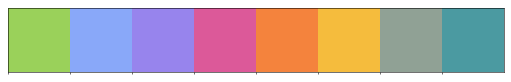

In [6]:
from matplotlib.colors import to_rgb, to_hex, ListedColormap
import seaborn as sns
import colorsys

niche_palette = [thyAgeing_colors['grass'], thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'],
                 thyAgeing_colors['orange'], thyAgeing_colors['yellow'],
                 thyAgeing_colors['mint'],thyAgeing_colors['teal']]

def tint_palette(palette, tint_factor=0.5):
    """Tint colors in a palette towards white by tint_factor (0=original, 1=white)."""
    tinted = []
    for c in palette:
        r, g, b = to_rgb(c)
        r = r + (1 - r) * tint_factor
        g = g + (1 - g) * tint_factor
        b = b + (1 - b) * tint_factor
        tinted.append(to_hex((r, g, b)))
    return tinted

def desaturate_palette(palette, saturation_scale=0.7):
    """
    Reduce saturation of hex colors in a palette.
    saturation_scale < 1 decreases saturation, > 1 increases
    """
    new_palette = []
    for c in palette:
        r, g, b = to_rgb(c)                   # convert to 0–1 rgb
        h, l, s = colorsys.rgb_to_hls(r, g, b) # convert to hls
        s = max(0, min(1, s * saturation_scale)) # scale saturation safely
        r2, g2, b2 = colorsys.hls_to_rgb(h, l, s)
        new_palette.append(to_hex((r2, g2, b2)))
    return new_palette

tinted_niche_palette = tint_palette(desaturate_palette(niche_palette, saturation_scale = 0.9), tint_factor=0.2)

sns.palplot(tinted_niche_palette)

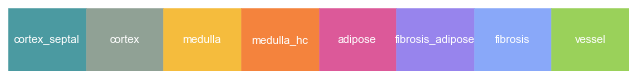

In [7]:
import matplotlib.pyplot as plt

# Plot thyAgeing_colors as a panel with keys as labels
fig, ax = plt.subplots(figsize=(8, 1))
for i, (name, hex_color) in enumerate(zip(xenium_adata.obs['morpho_niche_l2'].cat.categories, tinted_niche_palette[::-1])):
    ax.add_patch(plt.Rectangle((i, 0), 1, 1, color=hex_color))
    ax.text(i + 0.5, 0.5, name, va='center', ha='center', fontsize=10, color='white' if name not in ['yellow', 'mint', 'grass'] else 'black')
ax.set_xlim(0, len(tinted_niche_palette))
ax.set_ylim(0, 1)
ax.axis('off')
plt.tight_layout()
plt.show()

In [8]:

for lib in xenium_adata.obs['sample_ID'].unique():
    
#    ['Capsule/PVS', 'Cortex', 'Medulla', 'mcTEC-rich', 'InflammatoryPVS', 'Adipose']
    sq.pl.spatial_scatter(
        xenium_adata, 
        color=['morpho_niche_l2'], 
        library_key='sample_ID',
        library_id = lib,
         title = [''],
        legend_loc = None,
        shape=None,
        size=3, 
        img=None,
        palette = ListedColormap(tinted_niche_palette[::-1]),
        figsize=(6,6),
        ncols=3, frameon=False, save=f'{plots_path}/morpho_niches2/plotting/Xenium_morpho_niche_l2_{lib}_thyAge_tinted.png')
    

## H&E niche overlay plots

In [9]:
# Load integrated HnE data
he_adata = ad.read_h5ad(f'{data_path}/morphoFM/thyAging_CAM_morphoFM_mpp025_mf2_he_coral.h5ad')

niche_labels = pd.read_excel('/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/data/morpho_niches/morpho_niches.xlsx', index_col=0)[['morpho_niche_l3', 'morpho_niche_l2', 'morpho_niche_l1', 'morpho_niche_keep']].reset_index(names='leiden_r2.0')
niche_labels['leiden_r2.0'] = niche_labels['leiden_r2.0'].astype(str)
niche_labels['leiden_r2.0_concat'] = niche_labels['leiden_r2.0'].astype(str) + '_' + niche_labels['morpho_niche_l3'].astype(str)
niche_labels['leiden_r2.0_concat'] = pd.Categorical(niche_labels['leiden_r2.0_concat'], categories = sorted(niche_labels['leiden_r2.0_concat'].unique(), key = lambda x: int(x.split('_')[0])))
he_adata.obs = he_adata.obs.reset_index(names='tile_id').merge(niche_labels, on='leiden_r2.0', how='left').set_index('tile_id')
he_adata.obs['morpho_niche_l3'] = pd.Categorical(he_adata.obs['morpho_niche_l3'], categories=['cortex_septal','cortex_outer','cortex_dense', 'cortex', 'cortex_residual',
                    'medulla', 'medulla_hc', 'medulla_residual', 
                    'adipose', 'adipose_edge',
                    'fibrosis', 'fibrosis_adipose',
                    'endothelium_vessel', 'endothelium_edge',])
he_adata.obs['morpho_niche_l2'] = pd.Categorical(he_adata.obs['morpho_niche_l2'], categories=['cortex_septal','cortex', 'medulla', 'medulla_hc', 'adipose', 'fibrosis_adipose', 'fibrosis', 'vessel',])

he_adata.obs.head()

,sample,x0,y0,x1,y1,cx_img,cy_img,tile_size,stride,tissue_fraction,...,has_xenium,source,leiden_r1.0,leiden_r0.5,leiden_r2.0,morpho_niche_l3,morpho_niche_l2,morpho_niche_l1,morpho_niche_keep,leiden_r2.0_concat
tile_id,,,,,,,,,,,,,,,,,,,,,
A70-THY-0-FFPE-1_tile_00000000,A70-THY-0-FFPE-1,26208,1792,26432,2016,26320.0,1904.0,224,224,0.242128,...,False,CAM,4,10,29,fibrosis_adipose,fibrosis_adipose,fibrosis_adipose,True,29_fibrosis_adipose
A70-THY-0-FFPE-1_tile_00000001,A70-THY-0-FFPE-1,26432,1792,26656,2016,26544.0,1904.0,224,224,0.549685,...,False,CAM,12,4,17,fibrosis_adipose,fibrosis_adipose,fibrosis_adipose,True,17_fibrosis_adipose
A70-THY-0-FFPE-1_tile_00000002,A70-THY-0-FFPE-1,26656,1792,26880,2016,26768.0,1904.0,224,224,0.416354,...,False,CAM,15,1,6,fibrosis,fibrosis,fibrosis,True,6_fibrosis
A70-THY-0-FFPE-1_tile_00000003,A70-THY-0-FFPE-1,26880,1792,27104,2016,26992.0,1904.0,224,224,0.915537,...,False,CAM,0,1,6,fibrosis,fibrosis,fibrosis,True,6_fibrosis
A70-THY-0-FFPE-1_tile_00000004,A70-THY-0-FFPE-1,27104,1792,27328,2016,27216.0,1904.0,224,224,0.570532,...,False,CAM,12,2,25,fibrosis_adipose,fibrosis_adipose,fibrosis_adipose,True,25_fibrosis_adipose


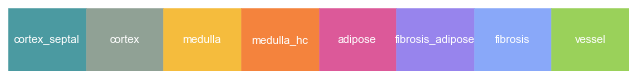

In [14]:
import matplotlib.pyplot as plt

# Plot thyAgeing_colors as a panel with keys as labels
fig, ax = plt.subplots(figsize=(8, 1))
for i, (name, hex_color) in enumerate(zip(he_adata.obs['morpho_niche_l2'].cat.categories, tinted_niche_palette[::-1])):
    ax.add_patch(plt.Rectangle((i, 0), 1, 1, color=hex_color))
    ax.text(i + 0.5, 0.5, name, va='center', ha='center', fontsize=10, color='white' if name not in ['yellow', 'mint', 'grass'] else 'black')
ax.set_xlim(0, len(tinted_niche_palette))
ax.set_ylim(0, 1)
ax.axis('off')
plt.tight_layout()
plt.show()

In [9]:
from scripts.morpho.preprocess_morpho import overlay_clusters_on_slide
from scripts.morpho.plot_morpho import tiles_to_original_coords,export_niches_to_geojson

In [21]:
xenium_samples = he_meta.loc[he_meta['has_xenium'], 'SampleID'].unique()

for sample in xenium_samples:
    tiff_path, orig_mpp = he_meta.loc[he_meta['SampleID'] == sample, ['file_path', 'resolution']].values[0]
        
    out, palette = overlay_clusters_on_slide(
        he_adata,
        sample=sample,
        tiff_path=tiff_path,
        orig_mpp=orig_mpp,
        alpha = 0.5,
        #clusters=clusters,
        label_col="morpho_niche_l2",
        palette=dict(zip(he_adata.obs['morpho_niche_l2'].cat.categories, tinted_niche_palette[::-1])),             # uses he_adata.uns["leiden_m2_r0.5_colors"]
        out_path=f"{plots_path}/morpho_niches2/plotting/thyAgeing_he_overlay_clusters_morpho_niche_l2_{sample}.png"
    )


level 5 shape: (1515, 935, 3), scale x,y: 0.031239, 0.031247
Sample A67.ome: painted 9981/12324 patches for clusters ['adipose', 'cortex', 'cortex_septal', 'fibrosis', 'fibrosis_adipose', 'medulla', 'medulla_hc', 'vessel']
✅ Saved cluster overlay: /nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/plots/morpho_niches2/plotting/thyAgeing_he_overlay_clusters_morpho_niche_l2_A67.ome.png
level 5 shape: (1816, 1131, 3), scale x,y: 0.031244, 0.031247
Sample A70.ome: painted 17840/20129 patches for clusters ['adipose', 'cortex', 'cortex_septal', 'fibrosis', 'fibrosis_adipose', 'medulla', 'medulla_hc', 'vessel']
✅ Saved cluster overlay: /nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/Spatial_analyses/plots/morpho_niches2/plotting/thyAgeing_he_overlay_clusters_morpho_niche_l2_A70.ome.png
level 5 shape: (1712, 1494, 3), scale x,y: 0.031239, 0.031247
Sample A72.ome: painted 21565/23494 patches for clusters ['adipose', 'cortex', 'cortex_septal', 'fibrosis', 'fibrosis_adip

/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts/plotting/utils.py:97: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby([x, hue]).agg(n_obs=(y, 'count'), mean=(y, lambda v: round(v.mean(), 4)), sd=(y, lambda v: round(v.std(), 4)), median=(y, lambda v: round(v.median(), 4))).to_csv(f'{save_stats}_summaryStats.csv', float_format='%.4f')
/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts/plotting/utils.py:428: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  kruskal_results = data.groupby(grouping_var).apply(_kruskal_or_default)
/nfs/team205/lm25/t

Performing Kruskal-Wallis and Dunn tests


/nfs/team205/lm25/thymus_projects/thymus_ageing_atlas/General_analysis/scripts/plotting/utils.py:156: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  g = sns.stripplot(data=data, x=x, y=y, order=order, dodge=True, jitter=True, hue=hue, hue_order=hue_order, size=1.5,
2026-07-28 09:23:53 | [INFO] maxp pruned
2026-07-28 09:23:53 | [INFO] LTSH dropped
2026-07-28 09:23:53 | [INFO] cmap pruned
2026-07-28 09:23:53 | [INFO] kern pruned
2026-07-28 09:23:53 | [INFO] post pruned
2026-07-28 09:23:53 | [INFO] PCLT dropped
2026-07-28 09:23:53 | [INFO] JSTF dropped
2026-07-28 09:23:53 | [INFO] DSIG dropped
2026-07-28 09:23:53 | [INFO] GSUB pruned
2026-07-28 09:23:53 | [INFO] glyf pruned
2026-07-28 09:23:53 | [INFO] Added gid0 to subset
2026-07-28 09:23:53 | [INFO] Added first four glyphs to subset
2026-07-28 09:23:53 | [INFO] Closing glyph list over 'GSUB': 36 glyphs before
2026-07-28 09:23:53 | 

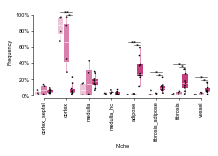

In [29]:
from plotting.utils import freq_by_donor, plot_grouped_boxplot, get_tint_palette
col_niche = 'morpho_niche_l2'
col_niche_levels = he_adata.obs[col_niche].cat.categories.tolist()
anno_df = he_adata.obs[['DonorID', 'SampleID', 'age_group', col_niche, 'morpho_niche_keep']].copy()
anno_df = anno_df.loc[anno_df['morpho_niche_keep']]
df = freq_by_donor(anno_df, sample_col = 'SampleID', donor_col = 'DonorID', summary_col=col_niche, add_meta = ['age_group'])

plot_grouped_boxplot(data = df, x = col_niche, y = 'mean_prop', hue = 'age_group', order = col_niche_levels, hue_order = ['infant', 'paed', 'adult'], 
                    palette = get_tint_palette(thyAgeing_colors['magenta'], min_tint = 0.3, n = 3), annotator_args = dict(line_offset = 1, text_offset = -3.5, line_offset_to_group = 0.03),
                     x_label = 'Niche', y_label = 'Frequency', legend_title = 'Age group', add_stats = True, format_percent = True, figsize = calc_figsize(height = 50, width = 70),
                     save_stats = f'{data_path}/morpho_niches/thyAgeing_{col_niche}_proportions_boxplot_')
plt.savefig(f'{plots_path}/morpho_niches2/plotting/thyAgeing_{col_niche}_proportions_boxplot_pub.pdf', bbox_inches='tight', dpi=300)

In [11]:
# Plot scCODA results
sccoda = pd.read_csv(f'{data_path}/morphoFM/morphoNiches_scCODA_DA_results_2026-07-28.csv')
sccoda['group'] = sccoda.Covariate.apply(lambda x: 'paed' if 'paed' in x else ('adult' if 'adult' in x else 'infant'))
sccoda['Cell Type'] = pd.Categorical(sccoda['Cell Type'], ['cortex_septal','cortex', 'medulla', 'medulla_hc', 'adipose', 'fibrosis_adipose', 'fibrosis', 'vessel'], ordered=True)
sccoda

,Covariate,Cell Type,Final Parameter,ETI 89% lower,ETI 89% upper,SD,Inclusion probability,Expected Sample,log2-fold change,group
0,"C(da_age_group, Treatment('infant'))[T.paed]",adipose,0.000000,-0.390000,0.720,0.25,0.4789,773.648700,0.438435,paed
1,"C(da_age_group, Treatment('infant'))[T.paed]",cortex,-0.441839,-1.200000,0.082,0.44,0.6583,13484.262905,-0.199004,paed
2,"C(da_age_group, Treatment('infant'))[T.paed]",cortex_septal,0.000000,-0.700000,0.410,0.41,0.4848,1511.893163,0.438435,paed
3,"C(da_age_group, Treatment('infant'))[T.paed]",fibrosis,0.000000,-0.500000,0.610,0.48,0.4778,773.648700,0.438435,paed
4,"C(da_age_group, Treatment('infant'))[T.paed]",fibrosis_adipose,0.000000,-0.450000,0.670,0.25,0.4835,855.014045,0.438435,paed
5,"C(da_age_group, Treatment('infant'))[T.paed]",medulla,0.000000,-0.400000,0.700,0.52,0.5014,1438.157264,0.438435,paed
6,"C(da_age_group, Treatment('infant'))[T.paed]",medulla_hc,0.000000,0.000000,0.000,0.24,0.0000,1557.937165,0.438435,paed
7,"C(da_age_group, Treatment('infant'))[T.paed]",vessel,0.000000,-0.460000,0.630,0.46,0.4915,700.026293,0.438435,paed
8,"C(da_age_group, Treatment('infant'))[T.adult]",adipose,2.824944,2.100000,3.500,0.25,1.0000,6570.633834,3.524717,adult
9,"C(da_age_group, Treatment('infant'))[T.adult]",cortex,-1.873062,-2.600000,-1.100,0.46,0.9953,1623.532092,-3.253073,adult


/tmp/ipykernel_657104/1550378925.py:7: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.barplot(
2026-07-28 10:10:51 | [INFO] maxp pruned
2026-07-28 10:10:51 | [INFO] LTSH dropped
2026-07-28 10:10:51 | [INFO] cmap pruned
2026-07-28 10:10:51 | [INFO] kern pruned
2026-07-28 10:10:51 | [INFO] post pruned
2026-07-28 10:10:51 | [INFO] PCLT dropped
2026-07-28 10:10:51 | [INFO] JSTF dropped
2026-07-28 10:10:51 | [INFO] DSIG dropped
2026-07-28 10:10:51 | [INFO] GSUB pruned
2026-07-28 10:10:51 | [INFO] glyf pruned
2026-07-28 10:10:51 | [INFO] Added gid0 to subset
2026-07-28 10:10:51 | [INFO] Added first four glyphs to subset
2026-07-28 10:10:51 | [INFO] Closing glyph list over 'GSUB': 31 glyphs before
2026-07-28 10:10:51 | [INFO] Glyph names: ['.notdef', '.null', 'F', 'N', 'P', 'a', 'b', 'c', 'd', 'e', 'f', 'four', 'h', 'i', 'l', 'm', 'minus', 'n', 'nonmarkingreturn', 'o', 'p', 'r', 's', 'space', 't', 'two', 'u', 'underscore', 'v', 'x', 'zero']

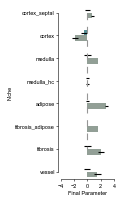

In [12]:
# Grouped horizontal barplot of scCODA results
groups = sccoda['group'].unique().tolist()

fig, ax = plt.subplots(figsize=calc_figsize(width=40, height=65))

palette = sns.color_palette(n_colors=len(groups))
sns.barplot(
    data=sccoda,
    x='Final Parameter',
    y='Cell Type',
    hue='group',
    order=sccoda['Cell Type'].cat.categories,
    hue_order=groups,
    orient='h',
    width = 0.5,
    dodge=True,
    errorbar=None,
    palette=tinted_niche_palette[::-1],
    ax=ax,
    legend = None,
    linewidth = 0,
)

for container, grp in zip(ax.containers, groups):
    sub = sccoda[sccoda['group'] == grp].set_index('Cell Type').reindex(cell_types)
    for patch, (_, row) in zip(container.patches, sub.iterrows()):
        err = row['SD']
        if pd.notna(err) and err > 0:
            y = patch.get_y() + patch.get_height() / 2
            x = patch.get_width()
            ax.errorbar(x, y, xerr=err, fmt='none', ecolor='black', capsize=0, lw=1)
ax.vlines(0, ymin = 0, ymax = 6, colors=thyAgeing_greys['grey3'], lw=1, ls='--')
ax.set_xlabel('Final Parameter')
ax.set_ylabel('Niche')
sns.despine(offset=2, trim=True)
plt.tight_layout()
plt.savefig(
    f'{plots_path}/morpho_niches2/plotting/sccoda_grouped_barplot_final_parameter_by_group.pdf',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

/tmp/ipykernel_657104/1192292735.py:8: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.barplot(
2026-07-28 10:11:48 | [INFO] maxp pruned
2026-07-28 10:11:48 | [INFO] LTSH dropped
2026-07-28 10:11:48 | [INFO] cmap pruned
2026-07-28 10:11:48 | [INFO] kern pruned
2026-07-28 10:11:48 | [INFO] post pruned
2026-07-28 10:11:48 | [INFO] PCLT dropped
2026-07-28 10:11:48 | [INFO] JSTF dropped
2026-07-28 10:11:48 | [INFO] DSIG dropped
2026-07-28 10:11:48 | [INFO] GSUB pruned
2026-07-28 10:11:48 | [INFO] glyf pruned
2026-07-28 10:11:48 | [INFO] Added gid0 to subset
2026-07-28 10:11:48 | [INFO] Added first four glyphs to subset
2026-07-28 10:11:48 | [INFO] Closing glyph list over 'GSUB': 31 glyphs before
2026-07-28 10:11:48 | [INFO] Glyph names: ['.notdef', '.null', 'N', 'a', 'b', 'c', 'd', 'e', 'f', 'four', 'g', 'h', 'hyphen', 'i', 'l', 'm', 'minus', 'n', 'nonmarkingreturn', 'o', 'p', 'r', 's', 'space', 't', 'two', 'u', 'underscore', 'v', 'x', 'z

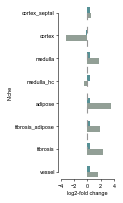

In [14]:
# Grouped horizontal barplot of scCODA results
groups = sccoda['group'].unique().tolist()
cell_types = sccoda['Cell Type'].cat.categories.tolist()

fig, ax = plt.subplots(figsize=calc_figsize(width=40, height=65))

palette = sns.color_palette(n_colors=len(groups))
sns.barplot(
    data=sccoda,
    x='log2-fold change',
    y='Cell Type',
    hue='group',
    order=sccoda['Cell Type'].cat.categories,
    hue_order=groups,
    orient='h',
    width = 0.5,
    dodge=True,
    errorbar=None,
    palette=tinted_niche_palette[::-1],
    ax=ax,
    legend = None,
    linewidth = 0,
)

ax.vlines(0, ymin = 0, ymax = 6, colors=thyAgeing_greys['grey3'], lw=1, ls='--')
ax.set_xlabel('log2-fold change')
ax.set_ylabel('Niche')
sns.despine(offset=2, trim=True)
plt.tight_layout()
plt.savefig(
    f'{plots_path}/morpho_niches2/plotting/sccoda_grouped_barplot_logFC_by_group.pdf',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

## Fibroblast visuals

### Gene program activity

In [8]:
import pprint
FB_programs = {    'AR_lipogenic_axis': ["AR", "CEBPB", "ACACA"],
                   'Lipogenesis_denovo': ["FASN", "ACLY", "ACACA", "SCD", "ELOVL6"],
    'FA_uptake_transport': ["CD36", "FABP4", "FABP1", "SLC27A1", "SLC27A2", "LPL"],
    'Beta_ox_longchain': ["CPT1A", "CPT1B", "CPT2", "ACADVL", "ACADL", "ACADM", "ACADS", "ACOX1", "ABCD1", "ABCD3"],
    'Ketone_body': ["HMGCS2", "BDH1", "OXCT1"],
    'Lipolysis': ["PNPLA2", "LIPE", "MGLL"],
    'TG_synthesis': ["DGAT1", "DGAT2", "GPAM"],
    'Cholesterol_synthesis': ["HMGCR", "HMGCS1", "SQLE", "MVD", "DHCR7"],
    'Cholesterol_uptake': ["LDLR", "SCARB1"],
    'Cholesterol_efflux': ["ABCA1", "ABCG1", "APOE", "NPC1"],
    'Lipid_efflux_transport': ["ABCA1", "ABCA6", "ABCA8", "ABCA9", "ABCA10", "APOD", "APOE", "LDLR"],
    'Lipid_master_regulators': ["PPARA", "PPARG", "PPARD", "PPARGC1A", "SREBF1", "SREBF2"],
    'Lipid_droplet_storage': ["PLIN1", "PLIN2", "PLIN4", "PLIN5", "CIDEC", "CIDEA", "BSCL2", "FITM1", "FITM2", "CEBPA", "MRAP", "AQP7"],
    'Futile_cycle_uncoupling': ["UCP1", "UCP2", "UCP3"],
    'COX_PGE2_axis': ["PTGS2", "PTGES"],
    'Paracrine_adipogenic_signaling': ["BMP2", "BMP4", "WNT5A", "DKK1", "DKK3", "SFRP1", "SFRP2", "SFRP4", "PDGFC", "PDGFD"],
    'Perivascular_ECM': ["MFAP5", "CD55", "FBN1", "SEMA3C", "PI16", "PCOLCE2", "COL4A1", "COL4A2", "HIF1A", "EPAS1"],
    'Adipogenic_signal_receptors': ["PTGER1", "PTGER2", "PTGER3", "PTGER4",  "BMPR1A", "BMPR2", "LRP5", "LRP6"],
    'ECM_activated': ["COL1A1", "COL3A1", "COL5A1", "SPARC"],
    'Retinoic_acid': ["ALDH1A1", "ALDH1A2", "ALDH1A3", "CRABP2", "RARB", "CYP26B1"],
    'CR_hormone_axis': ["FGF21", "LEP", "GHRL", "GHSR", "FGFR1", "KLB"],
    'Oxidative_stress': ["HMOX1", "SOD2", "GPX3", "NQO1", "TXN", "FTL", "FTH1"],
    'FB_senescent_SASP': ["SERPINE1", "HMOX1", "LMCD1", "RASAL2", "HAS1", "THBD", "CAVIN1"],
    'Cyt': ["IL18", 'TGFB1', "IL6", "CSF1", "CCL2", "FGF18", "IGFBP5",  "IL33", "KITLG", "IL7", "CXCL12", "FLT3LG", "TSLP"],
    'Cytokine_receptive':["IL1R1", "OSMR", "LIFR", "IL6ST", "SOCS3", "NFKB1", "TNFAIP6", "TGFBR1", "TGFBR2", "TGFBR3"],
    'Stress_IEG': ["FOS", "FOSB", "JUN", "JUNB", "EGR1", "ATF3", "ZFP36",
                   "HSPA1B", "HSP90AA1", "GADD45B", "NAMPT"],
}
FB_markers = {
    'Oxidative_stress': ["HMOX1", "SOD2", "GPX3", "NQO1", "TXN", "FTL", "FTH1"],
    'FB_Interlobular': ["MFAP5", "CD55", "FBN1", "SEMA3C", "PI16", "PCOLCE2",
                         "FBLN1", "CCDC80", "SCARA5", "COL14A1", "MFAP4", "TNXB", "CFD",
                         "PTGIS", "CPE"],
    'FB_intermediate': [ "PTX3", "FOSL1", "TNFRSF12A", "IL1RL1", "HMGA1", "MT1X",
                         "CD44", "IL1R1", "OSMR", "RUNX1", "NFKB1",  "CXCL12",  "IL6", "IL18", "CSF1", "CCL2"],
   'FB_activated': [ "ACTA2", "THY1", "LMCD1","FLNA", "FLNB", "CAVIN1", "TPM4", "JARID2", "PRG4", "ALDH1A3"],
        'FB_Fibrotic': ["SNAI1", "SNAI2","TGFB1", "IL33", "COL1A1", "COL3A1", "COL5A1", "SPARC", "SP1", "JUN"],
    'Lipid_storage': ["PLIN1", "PLIN4", "FABP4", "LIPE", "CIDEC", "CIDEA", "CEBPA", "LPL", "ACACB"],
    'FB_Adipo': [ "PPARG", "PPP1R1A", "MRAP", "AQP7", "PLXNA4", "GHR", "IGFBP3", "ADIPOQ", "IGFBP5"],  # reinforcing, clusters 0/9/4
    'FB': ['LUM', "FBN1", "PDGFRA", "PDGFRB", "VIM","COL3A1",
           "C7", "LAMA2", "FN1", "SPARCL1", "DCN",
             "ADH1B"],  # reinforcing pan-FB genes
    'FB_medullary': ["HLA-DRA", "CD74", "FRZB", "CCL19", "CCL21"],
    'FB_perilobular': ["COL15A1", "COLEC11", "PTN", "HAND2", "LAMC3", "C7", "ALDH1A1", "ALDH1A2", "CRABP2", "RARB", "CYP26B1"],

}

# Filter markers and programs to only include genes present in the he_adata.var_names
Fb_markers = {k:[v for v in vals if v in xenium_adata.var_names] for k, vals in FB_markers.items()}
Fb_programs = {k:[v for v in vals if v in xenium_adata.var_names] for k, vals in FB_programs.items()}

# Remove any empty entries from the dictionaries
Fb_markers = {k:v for k,v in Fb_markers.items() if v}
Fb_programs = {k:v for k,v in Fb_programs.items() if v}

pprint.pprint(Fb_markers, compact=True, width=120)
pprint.pprint(Fb_programs, compact=True, width=120)

{'FB': ['LUM', 'PDGFRA', 'PDGFRB'],
 'FB_Adipo': ['PPARG', 'MRAP', 'AQP7', 'GHR', 'ADIPOQ'],
 'FB_Fibrotic': ['SNAI1', 'SNAI2', 'TGFB1', 'IL33', 'COL5A1', 'SPARC', 'SP1'],
 'FB_Interlobular': ['MFAP5', 'CD55', 'SEMA3C', 'PI16', 'CCDC80', 'TNXB', 'PTGIS'],
 'FB_activated': ['THY1', 'FLNB', 'PRG4'],
 'FB_intermediate': ['PTX3', 'FOSL1', 'TNFRSF12A', 'IL1RL1', 'HMGA1', 'CD44', 'IL1R1', 'RUNX1', 'NFKB1', 'CXCL12',
                     'IL6', 'IL18', 'CSF1', 'CCL2'],
 'FB_medullary': ['HLA-DRA', 'FRZB', 'CCL19'],
 'FB_perilobular': ['COLEC11', 'RARB'],
 'Lipid_storage': ['PLIN1', 'PLIN4', 'LIPE', 'CIDEC', 'CEBPA', 'LPL', 'ACACB'],
 'Oxidative_stress': ['HMOX1', 'NQO1']}
{'AR_lipogenic_axis': ['AR', 'ACACA'],
 'Adipogenic_signal_receptors': ['PTGER2', 'PTGER3', 'PTGER4', 'BMPR1A', 'BMPR2', 'LRP5', 'LRP6'],
 'Beta_ox_longchain': ['CPT1A', 'ABCD1', 'ABCD3'],
 'COX_PGE2_axis': ['PTGS2', 'PTGES'],
 'CR_hormone_axis': ['FGF21', 'LEP', 'GHSR', 'FGFR1'],
 'Cholesterol_efflux': ['ABCA1', 'ABCG1', 'N

In [15]:
fb_sel = xenium_adata.obs['taa_l2_comb'].str.contains('Fb')
niche_dummies = pd.get_dummies(xenium_adata.obs['morpho_niche_l2'][fb_sel])

fb_genes = []
fb_genes.extend([gene for gene_list in Fb_markers.values() for gene in gene_list])
fb_genes.extend([gene for gene_list in Fb_programs.values() for gene in gene_list])
fb_genes = list(set(fb_genes))  # Remove duplicates
counts = xenium_adata[fb_sel, :][:, fb_genes].X.toarray()

counts.shape, niche_dummies.shape

((70621, 119), (70621, 8))

In [13]:
from scipy.sparse import csr_matrix
niche_counts = csr_matrix(niche_dummies.values.T) @ csr_matrix(counts)

Width exceeds the maximum width of 183 mm


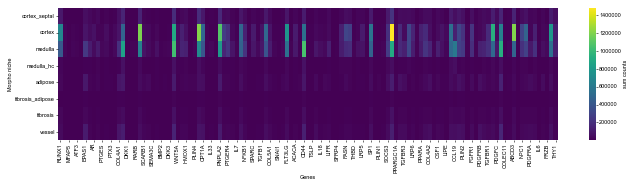

In [14]:
# Plot niche_counts as a heatmap
niche_counts_df = pd.DataFrame(
    niche_counts.toarray(),
    index=niche_dummies.columns,
    columns=fb_genes,
)

fig, ax = plt.subplots(figsize=calc_figsize(width=220, height=60))
sns.heatmap(
    niche_counts_df,
    cmap="viridis",
    ax=ax,
    cbar_kws={"label": "sum counts"},
)

ax.set_xlabel("Genes")
ax.set_ylabel("Morpho niche")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Subset to fibroblast cells and selected genes, normalize and log-transform
fb_xenium_adata = xenium_adata[fb_sel, :][:, fb_genes].copy()
sc.pp.normalize_total(fb_xenium_adata, target_sum=1e4)
sc.pp.log1p(fb_xenium_adata)

Width exceeds the maximum width of 183 mm


2026-07-29 11:16:24 | [INFO] maxp pruned
2026-07-29 11:16:24 | [INFO] LTSH dropped
2026-07-29 11:16:24 | [INFO] cmap pruned
2026-07-29 11:16:24 | [INFO] kern pruned
2026-07-29 11:16:24 | [INFO] post pruned
2026-07-29 11:16:24 | [INFO] PCLT dropped
2026-07-29 11:16:24 | [INFO] JSTF dropped
2026-07-29 11:16:24 | [INFO] DSIG dropped
2026-07-29 11:16:24 | [INFO] GSUB pruned
2026-07-29 11:16:24 | [INFO] glyf pruned
2026-07-29 11:16:24 | [INFO] Added gid0 to subset
2026-07-29 11:16:24 | [INFO] Added first four glyphs to subset
2026-07-29 11:16:24 | [INFO] Closing glyph list over 'GSUB': 64 glyphs before
2026-07-29 11:16:24 | [INFO] Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'eight', 'f', 'five', 'four', 'g', 'h', 'hyphen', 'i', 'l', 'm', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'percent', 'period', 'r', 's', 'seven', 'six', 'sp

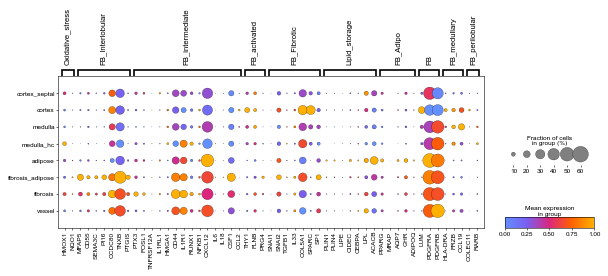

In [24]:
cmap = sns.blend_palette([thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'], thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True,)

sc.pl.DotPlot(fb_xenium_adata, var_names=Fb_markers, groupby='morpho_niche_l2', standard_scale='var', cmap=cmap, figsize=calc_figsize(width=220, height=60), 
              #save=f'{plots_path}/morpho_niches2/plotting/fb_genes_dotplot_morpho_niche_l2.pdf'
              ).savefig(f'{plots_path}/morpho_niches2/plotting/fb_genes_dotplot_morpho_niche_l2.pdf', bbox_inches='tight', dpi=300)

Width exceeds the maximum width of 183 mm


2026-07-29 11:16:17 | [INFO] maxp pruned
2026-07-29 11:16:17 | [INFO] LTSH dropped
2026-07-29 11:16:17 | [INFO] cmap pruned
2026-07-29 11:16:17 | [INFO] kern pruned
2026-07-29 11:16:17 | [INFO] post pruned
2026-07-29 11:16:17 | [INFO] PCLT dropped
2026-07-29 11:16:17 | [INFO] JSTF dropped
2026-07-29 11:16:17 | [INFO] DSIG dropped
2026-07-29 11:16:17 | [INFO] GSUB pruned
2026-07-29 11:16:17 | [INFO] glyf pruned
2026-07-29 11:16:17 | [INFO] Added gid0 to subset
2026-07-29 11:16:17 | [INFO] Added first four glyphs to subset
2026-07-29 11:16:17 | [INFO] Closing glyph list over 'GSUB': 64 glyphs before
2026-07-29 11:16:17 | [INFO] Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'a', 'b', 'c', 'd', 'e', 'eight', 'f', 'five', 'four', 'g', 'h', 'i', 'k', 'l', 'm', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'percent', 'period', 'r', 's', 'seven', 'six', 'space', 't

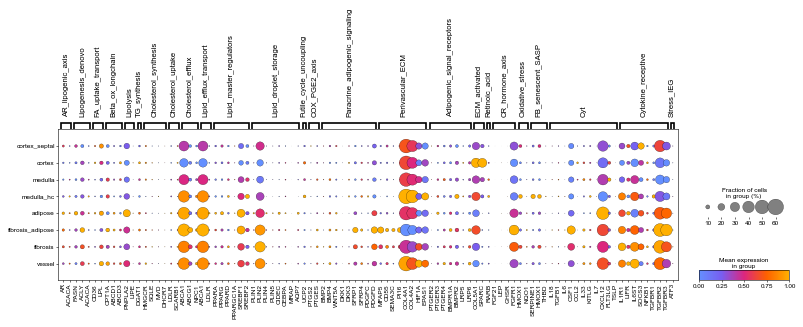

In [23]:
sc.pl.DotPlot(fb_xenium_adata, var_names=Fb_programs, groupby='morpho_niche_l2', standard_scale='var', cmap=cmap, figsize=calc_figsize(width=300, height=60), 
              #save=f'{plots_path}/morpho_niches2/plotting/fb_genes_dotplot_morpho_niche_l2.pdf'
              ).savefig(f'{plots_path}/morpho_niches2/plotting/fb_programs_dotplot_morpho_niche_l2.pdf', bbox_inches='tight', dpi=300)

In [25]:
fb_xenium_adata.obs.columns

Index(['sample_ID', 'donor', 'chemistry_simple', 'cells_spatial',
       '_scvi_batch', '_scvi_labels', 'X_scVI_shortlist_v1_leiden_1',
       'level_0_pred', 'level_0_prob', 'level_1_pred', 'level_1_prob',
       'level_2_pred', 'level_2_prob', 'level_3_pred', 'level_3_prob',
       'level_4_pred', 'level_4_prob', 'level_5_pred', 'level_5_prob',
       'level_2v2_pred', 'level_2v2_prob', 'level_3v2_pred', 'level_3v2_prob',
       'taa_l2_comb', 'taa_l3_comb', 'niche_cellcharter3_v2_comb',
       'niche_cellcharter6_comb', 'SampleID_he', 'patch_col', 'patch_row',
       'patchID', 'leiden_r2.0', 'morpho_niche_l3', 'morpho_niche_l2',
       'morpho_niche_l1', 'morpho_niche_keep', 'leiden_r2.0_concat'],
      dtype='object')

Width exceeds the maximum width of 183 mm


2026-07-29 11:24:00 | [INFO] maxp pruned
2026-07-29 11:24:00 | [INFO] LTSH dropped
2026-07-29 11:24:00 | [INFO] cmap pruned
2026-07-29 11:24:00 | [INFO] kern pruned
2026-07-29 11:24:00 | [INFO] post pruned
2026-07-29 11:24:00 | [INFO] PCLT dropped
2026-07-29 11:24:00 | [INFO] JSTF dropped
2026-07-29 11:24:00 | [INFO] DSIG dropped
2026-07-29 11:24:00 | [INFO] GSUB pruned
2026-07-29 11:24:00 | [INFO] glyf pruned
2026-07-29 11:24:00 | [INFO] Added gid0 to subset
2026-07-29 11:24:00 | [INFO] Added first four glyphs to subset
2026-07-29 11:24:00 | [INFO] Closing glyph list over 'GSUB': 65 glyphs before
2026-07-29 11:24:00 | [INFO] Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'a', 'b', 'c', 'd', 'e', 'eight', 'f', 'five', 'four', 'g', 'h', 'i', 'k', 'l', 'm', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'percent', 'period', 'r', 's', 'seven', 'six', 'sp

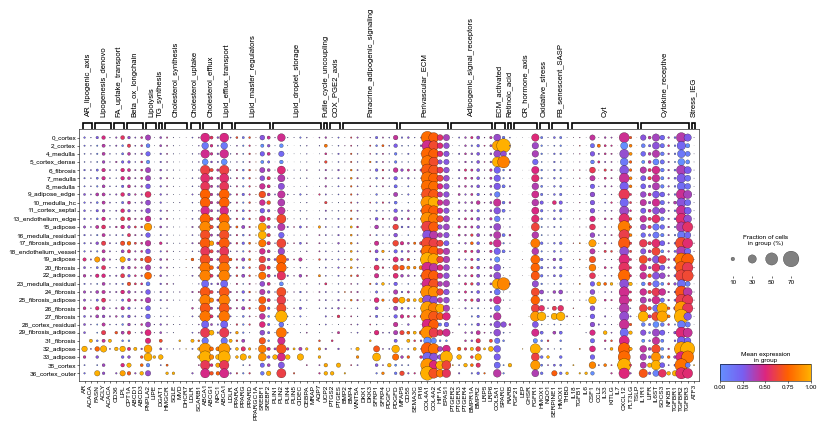

In [27]:
sc.pl.DotPlot(fb_xenium_adata, var_names=Fb_programs, groupby='leiden_r2.0_concat', standard_scale='var', cmap=cmap, figsize=calc_figsize(width=300, height=100), 
              #save=f'{plots_path}/morpho_niches2/plotting/fb_genes_dotplot_morpho_niche_l2.pdf'
              ).savefig(f'{plots_path}/morpho_niches2/plotting/fb_programs_dotplot_leiden_r2.0_concat.pdf', bbox_inches='tight', dpi=300)

In [29]:
fb_xenium_adata.obs['morpho_niche_l2'].value_counts()

morpho_niche_l2
medulla             26538
adipose             13444
vessel              11770
cortex_septal        7376
cortex               5046
fibrosis             4478
fibrosis_adipose     1519
medulla_hc            450
Name: count, dtype: int64

### Spatial distribution

In [13]:
ct_to_plot = [c for c in col_cell_type_levels_broad if c in anno_levels.loc[anno_levels['taa_l0'].isin(['Stroma', 'Vasculature'])]['taa_l3'].unique()]
ct_to_plot

['Fb-interlo',
 'Fb-perilo',
 'Fb-med',
 'Fb-interm',
 'Fb-adipo',
 'Adipocyte',
 'EC-art',
 'EC-cap',
 'EC-cap_lipid',
 'EC-ven',
 'EC-peri',
 'EC-lymphatic',
 'SMC',
 'Pericyte']

In [28]:
from matplotlib.backends.backend_pdf import PdfPages
from plotting.utils import create_diverging_palette

def group_enrichment(obs, cluster_col, anno_col, pseudocount=0.5, min_cells=10):
    ct = pd.crosstab(obs[cluster_col], obs[anno_col])          # one pooled table
    ct = ct.loc[:, ct.sum(0) >= min_cells]                     # drop ultra-rare types
    N   = ct.values.sum()
    exp = ct.sum(1).values[:, None] @ ct.sum(0).values[None, :] / N
    log2oe = np.log2((ct.values + pseudocount) / (exp + pseudocount))
    return pd.DataFrame(log2oe, index=ct.index, columns=ct.columns)

age_group_dict = {'infant' : 'U', 'paed' : 'Z', 'adult' : 'A'}
ctoi='stroma_vasc'

# Perform cluster enrichment analysis for xenium data
cell_anno_col = 'taa_l3_comb'
niche_anno_col = 'morpho_niche_l2'

mode = 'log2oe'
min_max = False

mode_name = mode if not min_max else f'{mode}_minmax'

with PdfPages(f'{plots_path}/morpho_niches2/plotting/thyAging_morphoFM_patch_{ctoi}_{niche_anno_col}_{cell_anno_col}_{mode_name}_heatmap_perAgeGroup.pdf') as pdf:
    for age_group in age_group_dict.keys():

        patch_summary = xenium_adata[xenium_adata.obs['donor'].str.startswith(age_group_dict[age_group]), :].obs[['donor', 'patchID', cell_anno_col, niche_anno_col]].copy()
                
        # LogOE enrichment
        summary = group_enrichment(patch_summary, niche_anno_col, cell_anno_col).melt(ignore_index=False, var_name=cell_anno_col, value_name='mean_log2oe').reset_index(names=niche_anno_col)
        summary = summary.loc[summary[cell_anno_col].isin(ct_to_plot)]
        summary[cell_anno_col] = pd.Categorical(summary[cell_anno_col], categories=ct_to_plot, ordered=True)
        summary = summary.dropna(subset=cell_anno_col)
        plot_df = summary.pivot(index=niche_anno_col, columns=cell_anno_col, values='mean_log2oe')

        # Order axes 
        plot_df = plot_df.reindex(index=summary[niche_anno_col].cat.categories[::-1])
        plot_df = plot_df.reindex(columns=summary[cell_anno_col].cat.categories)
        plot_df.fillna(0, inplace=True)

        # Cell counts per niche
        counts = pd.crosstab(patch_summary[niche_anno_col], patch_summary[cell_anno_col])  # cells per (niche, celltype)
        counts  = counts.reindex(index=plot_df.index, columns=plot_df.columns).fillna(0)
        
        if mode == 'colprop':
            counts = counts.div(counts.sum(axis=0), axis=1)  # column-normalized -> sums to 1 down each cell-type column
            
            if min_max:
                        counts = counts.div(counts.max(axis=0), axis=1)  # min-max normalization per cell type
                        
        if mode == 'rowprop':
            counts = counts.div(counts.sum(axis=1), axis=0)  # row-normalized -> sums to 1 across each niche row
            
            if min_max:
                counts = counts.div(counts.max(axis=1), axis=0)  # min-max normalization per niche

        # Per-niche stats from the FULL (pre-filter) patch_summary, aligned to the plotted niches
        cells_per_niche   = patch_summary.groupby(niche_anno_col, observed=True).size().reindex(plot_df.index).fillna(0)
        patches_per_niche = (patch_summary.groupby(niche_anno_col, observed=True)['patchID']
                            .nunique().reindex(plot_df.index).fillna(0))

        ny, nx = plot_df.shape
        fig = plt.figure(figsize=calc_figsize(width=nx*3+15+15, height=ny*3+15))
        gs  = fig.add_gridspec(1, 4, width_ratios=[6, 1, 1, 0.25], wspace=0.06)
        ax0 = fig.add_subplot(gs[0])
        ax1 = fig.add_subplot(gs[1], sharey=ax0)
        ax2 = fig.add_subplot(gs[2], sharey=ax0)
        cax = fig.add_subplot(gs[3])          # dedicated colorbar axes

        if mode == 'log2oe':
            cmap = create_diverging_palette(thyAgeing_colors['teal'], thyAgeing_colors['orange'], s=90, l=60, as_cmap=True)
            vmax = 3
            sns.heatmap(
                plot_df,
                cmap=cmap,
                center=0, vmax=vmax, vmin=-vmax,
                cbar_ax=cax,
                cbar_kws={'label': 'mean_log2oe'},
                xticklabels=True,
                yticklabels=True,
                ax=ax0,
            )
        elif mode == 'log2oe_pos':
            if not min_max:
                plot_df = plot_df.clip(lower=0)
                cmap = sns.blend_palette([thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'], thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True,)
                vmax = 3
                sns.heatmap(
                    plot_df,
                    cmap=cmap,
                    vmax=vmax,
                    cbar_ax=cax,
                    cbar_kws={'label': f'{mode_name}'},
                    xticklabels=True,
                    yticklabels=True,
                    ax=ax0,
                )
            else:
                plot_df = plot_df.clip(lower=0)
                plot_df = plot_df.div(plot_df.max(axis=0), axis=1)  # min-max normalization per cell type
                cmap = sns.blend_palette([thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'], thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True,)
                vmax = 1
                sns.heatmap(
                    plot_df,
                    cmap=cmap,
                    vmax=vmax,
                    cbar_ax=cax,
                    cbar_kws={'label': f'{mode_name}'},
                    xticklabels=True,
                    yticklabels=True,
                    ax=ax0,
                )
        else:
            cmap = sns.blend_palette(
                [thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'],
                 thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True)
            vmax = 1 if mode in ('colprop', 'rowprop') else counts.values.max()
            sns.heatmap(
                counts,                        # was plot_df, and cmap=counts
                cmap=cmap,
                vmax=vmax,
                cbar_ax=cax,
                cbar_kws={'label': f'{mode_name}'},
                xticklabels=True,
                yticklabels=True,
                ax=ax0,
            )

        ax0.set_xlabel(cell_anno_col)
        ax0.set_ylabel(niche_anno_col)

        # Bar plots for # patches and # cells per niche
        y = np.arange(ny) + 0.5                # heatmap rows are centred on half-integers
        ax1.barh(y, patches_per_niche.values, color='0.6', height=0.7)
        ax2.barh(y, cells_per_niche.values,   color='0.6', height=0.7)
        for a, title, vals in [(ax1, '# patches', patches_per_niche), (ax2, '# cells', cells_per_niche)]:
            a.set_xscale('log')
            a.set_xlim(1, max(vals.max() * 1.5, 10))
            a.set_title(title, fontsize=6)
            a.tick_params(labelleft=False, labelsize=5)
            for s in ('top', 'right'):
                a.spines[s].set_visible(False)

        fig.suptitle(f'Age group: {age_group}', fontsize=8)
        fig.tight_layout(); pdf.savefig(fig); plt.close(fig)


/tmp/ipykernel_3319876/160038093.py:145: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); pdf.savefig(fig); plt.close(fig)
/tmp/ipykernel_3319876/160038093.py:145: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); pdf.savefig(fig); plt.close(fig)
/tmp/ipykernel_3319876/160038093.py:145: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); pdf.savefig(fig); plt.close(fig)
2026-08-04 16:42:27 | [INFO] maxp pruned
2026-08-04 16:42:27 | [INFO] LTSH dropped
2026-08-04 16:42:27 | [INFO] cmap pruned
2026-08-04 16:42:27 | [INFO] kern pruned
2026-08-04 16:42:27 | [INFO] post pruned
2026-08-04 16:42:27 | [INFO] PCLT dropped
2026-08-04 16:42:27 | [INFO] JSTF dropped
2026-08-04 16:42:27 | [INFO] DSIG dropped
2026-08-04 16:42:27 | [INFO] GSUB pruned


## Recirculating immune cells

In [31]:
ct_to_plot = ['T_CD8_recirc', 'T_CD4_recirc', 'T_Treg_recirc', 'ILC', 'NK' ,'B_mem', 'B_GC-like', 'B_plasma', 'Neutrophil','Mono', 'Mac', 'DC1', 'DC2', 'aDC', 'pDC', 'Mast']

In [36]:
from matplotlib.backends.backend_pdf import PdfPages
from plotting.utils import create_diverging_palette

def group_enrichment(obs, cluster_col, anno_col, pseudocount=0.5, min_cells=10):
    ct = pd.crosstab(obs[cluster_col], obs[anno_col])          # one pooled table
    ct = ct.loc[:, ct.sum(0) >= min_cells]                     # drop ultra-rare types
    N   = ct.values.sum()
    exp = ct.sum(1).values[:, None] @ ct.sum(0).values[None, :] / N
    log2oe = np.log2((ct.values + pseudocount) / (exp + pseudocount))
    return pd.DataFrame(log2oe, index=ct.index, columns=ct.columns)

age_group_dict = {'infant' : 'U', 'paed' : 'Z', 'adult' : 'A'}
ctoi='recirc'

# Perform cluster enrichment analysis for xenium data
cell_anno_col = 'taa_l3_comb'
niche_anno_col = 'morpho_niche_l2'

mode = 'log2oe'
min_max = False

mode_name = mode if not min_max else f'{mode}_minmax'

with PdfPages(f'{plots_path}/morpho_niches2/plotting/thyAging_morphoFM_patch_{ctoi}_{niche_anno_col}_{cell_anno_col}_{mode_name}_heatmap_perAgeGroup.pdf') as pdf:
    for age_group in age_group_dict.keys():

        patch_summary = xenium_adata[xenium_adata.obs['donor'].str.startswith(age_group_dict[age_group]), :].obs[['donor', 'patchID', cell_anno_col, niche_anno_col]].copy()
                
        # LogOE enrichment
        summary = group_enrichment(patch_summary, niche_anno_col, cell_anno_col).melt(ignore_index=False, var_name=cell_anno_col, value_name='mean_log2oe').reset_index(names=niche_anno_col)
        summary = summary.loc[summary[cell_anno_col].isin(ct_to_plot)]
        summary[cell_anno_col] = pd.Categorical(summary[cell_anno_col], categories=ct_to_plot, ordered=True)
        summary = summary.dropna(subset=cell_anno_col)
        plot_df = summary.pivot(index=niche_anno_col, columns=cell_anno_col, values='mean_log2oe')

        # Order axes 
        plot_df = plot_df.reindex(index=summary[niche_anno_col].cat.categories[::-1])
        plot_df = plot_df.reindex(columns=summary[cell_anno_col].cat.categories)
        plot_df.fillna(0, inplace=True)

        # Cell counts per niche
        counts = pd.crosstab(patch_summary[niche_anno_col], patch_summary[cell_anno_col])  # cells per (niche, celltype)
        counts  = counts.reindex(index=plot_df.index, columns=plot_df.columns).fillna(0)
        
        if mode == 'colprop':
            counts = counts.div(counts.sum(axis=0), axis=1)  # column-normalized -> sums to 1 down each cell-type column
            
            if min_max:
                        counts = counts.div(counts.max(axis=0), axis=1)  # min-max normalization per cell type
                        
        if mode == 'rowprop':
            counts = counts.div(counts.sum(axis=1), axis=0)  # row-normalized -> sums to 1 across each niche row
            
            if min_max:
                counts = counts.div(counts.max(axis=1), axis=0)  # min-max normalization per niche

        # Per-niche stats from the FULL (pre-filter) patch_summary, aligned to the plotted niches
        cells_per_niche   = patch_summary.groupby(niche_anno_col, observed=True).size().reindex(plot_df.index).fillna(0)
        patches_per_niche = (patch_summary.groupby(niche_anno_col, observed=True)['patchID']
                            .nunique().reindex(plot_df.index).fillna(0))

        ny, nx = plot_df.shape
        fig = plt.figure(figsize=calc_figsize(width=nx*3+15+15, height=ny*3+5))
        gs  = fig.add_gridspec(1, 4, width_ratios=[6, 1, 1, 0.25], wspace=0.06)
        ax0 = fig.add_subplot(gs[0])
        ax1 = fig.add_subplot(gs[1], sharey=ax0)
        ax2 = fig.add_subplot(gs[2], sharey=ax0)
        cax = fig.add_subplot(gs[3])          # dedicated colorbar axes

        if mode == 'log2oe':
            cmap = create_diverging_palette(thyAgeing_colors['teal'], thyAgeing_colors['orange'], s=90, l=60, as_cmap=True)
            vmax = 3
            sns.heatmap(
                plot_df,
                cmap=cmap,
                center=0, vmax=vmax, vmin=-vmax,
                cbar_ax=cax,
                cbar_kws={'label': 'mean_log2oe'},
                xticklabels=True,
                yticklabels=True,
                ax=ax0,
            )
        elif mode == 'log2oe_pos':
            if not min_max:
                plot_df = plot_df.clip(lower=0)
                cmap = sns.blend_palette([thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'], thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True,)
                vmax = 3
                sns.heatmap(
                    plot_df,
                    cmap=cmap,
                    vmax=vmax,
                    cbar_ax=cax,
                    cbar_kws={'label': f'{mode_name}'},
                    xticklabels=True,
                    yticklabels=True,
                    ax=ax0,
                )
            else:
                plot_df = plot_df.clip(lower=0)
                plot_df = plot_df.div(plot_df.max(axis=0), axis=1)  # min-max normalization per cell type
                cmap = sns.blend_palette([thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'], thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True,)
                vmax = 1
                sns.heatmap(
                    plot_df,
                    cmap=cmap,
                    vmax=vmax,
                    cbar_ax=cax,
                    cbar_kws={'label': f'{mode_name}'},
                    xticklabels=True,
                    yticklabels=True,
                    ax=ax0,
                )
        else:
            cmap = sns.blend_palette(
                [thyAgeing_colors['blue'], thyAgeing_colors['purple'], thyAgeing_colors['magenta'],
                 thyAgeing_colors['orange'], thyAgeing_colors['yellow']], as_cmap=True)
            vmax = 1 if mode in ('colprop', 'rowprop') else counts.values.max()
            sns.heatmap(
                counts,                        # was plot_df, and cmap=counts
                cmap=cmap,
                vmax=vmax,
                cbar_ax=cax,
                cbar_kws={'label': f'{mode_name}'},
                xticklabels=True,
                yticklabels=True,
                ax=ax0,
            )

        ax0.set_xlabel(cell_anno_col)
        ax0.set_ylabel(niche_anno_col)

        # Bar plots for # patches and # cells per niche
        y = np.arange(ny) + 0.5                # heatmap rows are centred on half-integers
        ax1.barh(y, patches_per_niche.values, color='0.6', height=0.7)
        ax2.barh(y, cells_per_niche.values,   color='0.6', height=0.7)
        for a, title, vals in [(ax1, '# patches', patches_per_niche), (ax2, '# cells', cells_per_niche)]:
            a.set_xscale('log')
            a.set_xlim(1, max(vals.max() * 1.5, 10))
            a.set_title(title, fontsize=6)
            a.tick_params(labelleft=False, labelsize=5)
            for s in ('top', 'right'):
                a.spines[s].set_visible(False)

        fig.suptitle(f'Age group: {age_group}', fontsize=8)
        fig.tight_layout(); pdf.savefig(fig); plt.close(fig)


/tmp/ipykernel_3319876/1102450956.py:145: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); pdf.savefig(fig); plt.close(fig)
/tmp/ipykernel_3319876/1102450956.py:145: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); pdf.savefig(fig); plt.close(fig)
/tmp/ipykernel_3319876/1102450956.py:145: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); pdf.savefig(fig); plt.close(fig)
2026-08-04 16:55:21 | [INFO] maxp pruned
2026-08-04 16:55:21 | [INFO] LTSH dropped
2026-08-04 16:55:21 | [INFO] cmap pruned
2026-08-04 16:55:21 | [INFO] kern pruned
2026-08-04 16:55:21 | [INFO] post pruned
2026-08-04 16:55:21 | [INFO] PCLT dropped
2026-08-04 16:55:21 | [INFO] JSTF dropped
2026-08-04 16:55:21 | [INFO] DSIG dropped
2026-08-04 16:55:21 | [INFO] GSUB prun

## Combined area quant for H&E and Visium

In [10]:
visium_quant = pd.read_csv('/nfs/team205/vk8/projects/thymus_ageing_atlas/Spatial_analyses/data/ThyAge_spatial_anno_df_full_v3_2025-09-24.csv')
visium_quant = visium_quant.loc[visium_quant['chemistry_simple'] != 'Xenium']

latest_meta_path = get_latest_version(dir = f'{general_data_path}/metadata', file_prefix='Thymus_ageing_metadata')
latest_meta = pd.read_excel(latest_meta_path)

Latest file: Thymus_ageing_metadata_v30_2026-07-09.xlsx


In [11]:
visium_quant

,SampleID,Cortex,Medulla,Edge,PVS,HC,fat,fibrotic,Adipose,HCs,...,Medulla_full_freq,Non-functional_freq,Cortex_full_freq2,Medulla_full_freq2,Sample_hr,donor,age_group,age_months,chemistry_simple,age_years
0,TA11486162,4686583.0,1645392.0,945747.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.226086,0.000000,0.773914,0.226086,Z4_FO3_03,Z4,paed_early,3.00,Visium_OCT,0.25
1,TA11556493,3938357.0,1520945.0,994571.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.235664,0.000000,0.764336,0.235664,Z4_FO3_01,Z4,paed_early,3.00,Visium_OCT,0.25
2,TA11556494,1128361.0,414840.0,232714.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.233592,0.000000,0.766408,0.233592,Z4_FO3_02,Z4,paed_early,3.00,Visium_OCT,0.25
3,WSSS_THYst9142088,2624996.0,1549012.0,439245.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.335774,0.000000,0.664226,0.335774,U11_FO2_01,U11,paed_early,5.00,Visium_OCT,0.42
4,WSSS_THYst9142089,2748621.0,1375415.0,581700.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.292285,0.000000,0.707715,0.292285,U11_FO2_02,U11,paed_early,5.00,Visium_OCT,0.42
5,WSSS_THYst9518030,3085660.0,1314731.0,723679.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.256579,0.000000,0.743421,0.256579,U11_FO2_03,U11,paed_early,5.00,Visium_OCT,0.42
6,WSSS_THYst9142086,2408704.0,757228.0,447679.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.209549,0.000000,0.790451,0.209549,U09_FO1a_01,U09,paed_early,6.00,Visium_OCT,0.50
7,WSSS_THYst9142087,2660833.0,882587.0,437835.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.221686,0.000000,0.778314,0.221686,U09_FO1a_02,U09,paed_early,6.00,Visium_OCT,0.50
8,WSSS_THYst9518032,3179638.0,804041.0,965582.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.162457,0.000000,0.837543,0.162457,U09_FO1a_03,U09,paed_early,6.00,Visium_OCT,0.50
9,WSSS_THYst9518033,3241712.0,878458.0,723277.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.181370,0.000000,0.818630,0.181370,U09_FO1a_04,U09,paed_early,6.00,Visium_OCT,0.50


In [13]:
from plotting.utils import freq_by_donor, plot_grouped_boxplot, get_tint_palette
col_niche = 'morpho_niche_l2'
col_niche_levels = he_adata.obs[col_niche].cat.categories.tolist()
anno_df = he_adata.obs[['DonorID', 'SampleID', 'age_group', col_niche, 'morpho_niche_keep']].copy()
anno_df = anno_df.merge(latest_meta[['donor', 'age_months']].drop_duplicates(), left_on = 'DonorID', right_on='donor')
anno_df = anno_df.loc[anno_df['morpho_niche_keep']]
df = freq_by_donor(anno_df, sample_col = 'SampleID', donor_col = 'DonorID', summary_col=col_niche, add_meta = ['age_group', 'age_months'])
hne_groups = {'medulla' : ['medulla', 'medulla_hc'],
              'cortex' : ['cortex', 'cortex_septal'],
              'non-func' : ['adipose', 'fibrosis','fibrosis_adipose', 'vessel']}
hne_map = {niche: group for group, niches in hne_groups.items() for niche in niches}
df['niche_simple'] = df['morpho_niche_l2'].map(hne_map)
df.rename(columns={'DonorID' : 'donor'}, inplace=True)
df = df.groupby(['donor', 'age_group', 'age_months', 'niche_simple'], observed = True).agg({'mean_prop' : 'sum'}).reset_index()
df

,donor,age_group,age_months,niche_simple,mean_prop
0,A43,adult,420.0,cortex,0.089645
1,A43,adult,420.0,medulla,0.188062
2,A43,adult,420.0,non-func,0.722294
3,A45,adult,228.0,cortex,0.153670
4,A45,adult,228.0,medulla,0.323810
5,A45,adult,228.0,non-func,0.522520
6,A53,adult,348.0,cortex,0.196045
7,A53,adult,348.0,medulla,0.154108
8,A53,adult,348.0,non-func,0.649847
9,A56,adult,336.0,cortex,0.069909


In [43]:
print('H&E number of donors: {}, Samples: {}'.format(anno_df.DonorID.nunique(), anno_df.SampleID.nunique()))

print('Visium number of donors: {}, Samples: {}'.format(visium_quant.donor.nunique(), visium_quant.SampleID.nunique()))

H&E number of donors: 17, Samples: 32
Visium number of donors: 16, Samples: 30


In [32]:
visium_map = {'Cortex_full_freq' : 'cortex',
              'Medulla_full_freq' : 'medulla',
              'Non-functional_freq' : 'non-func'}
visium_df = visium_quant[['Cortex_full_freq','Medulla_full_freq', 'Non-functional_freq', 'donor', 'age_group', 'age_months']].copy()
visium_df = visium_df.melt(id_vars=['donor', 'age_group', 'age_months'], var_name='niche_simple', value_name='freq')
visium_df['niche_simple'] = visium_df['niche_simple'].map(visium_map)
visium_df.rename(columns = {'freq':'mean_prop'}, inplace=True)
visium_df = visium_df.groupby(['donor', 'age_group', 'age_months', 'niche_simple'], observed = True).agg({'mean_prop' : 'mean'}).reset_index()

visium_df

,donor,age_group,age_months,niche_simple,mean_prop
0,A43,adult,420.00,cortex,0.000000
1,A43,adult,420.00,medulla,0.068388
2,A43,adult,420.00,non-func,0.931612
3,A45,adult,228.00,cortex,0.043373
4,A45,adult,228.00,medulla,0.296397
5,A45,adult,228.00,non-func,0.660230
6,NIHTHY0057,paed_late,60.00,cortex,0.646681
7,NIHTHY0057,paed_late,60.00,medulla,0.285315
8,NIHTHY0057,paed_late,60.00,non-func,0.068004
9,NIHTHY0081,paed_early,0.23,cortex,0.685355


In [33]:
full_df = pd.concat([df, visium_df], axis=0, keys=['H&E', 'visium']).reset_index(level=0).rename(columns={'level_0':'source'})
full_df

,source,donor,age_group,age_months,niche_simple,mean_prop
0,H&E,A43,adult,420.0,cortex,0.089645
1,H&E,A43,adult,420.0,medulla,0.188062
2,H&E,A43,adult,420.0,non-func,0.722294
3,H&E,A45,adult,228.0,cortex,0.153670
4,H&E,A45,adult,228.0,medulla,0.323810
...,...,...,...,...,...,...
43,visium,Z4,paed_early,3.0,medulla,0.231781
44,visium,Z4,paed_early,3.0,non-func,0.000000
45,visium,Z6,paed_early,30.0,cortex,0.654753
46,visium,Z6,paed_early,30.0,medulla,0.345247


In [18]:
# --- smoother used for the niche-vs-age trend lines -------------------------
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.special import logit, expit
from scipy.interpolate import interp1d


def log_age_grid(lo, hi, n=300, offset=1.0):
    """Geometric-ish grid on log(age + offset), valid when age == 0."""
    return np.exp(np.linspace(np.log(lo + offset), np.log(hi + offset), n)) - offset


def smooth_fit(x, y, groups=None, method='spline', spline_df=4, frac=0.65,
               logit_y=True, log_x=True, x_offset=1.0, n_boot=500, ci=95,
               xs=None, seed=0):
    """Smooth y ~ x and return (xs, fit, lo, hi), the band being a bootstrap CI.

    method   : 'spline'   natural cubic spline (df knots) fitted by OLS
               'lowess'   local regression (statsmodels), `frac` = span
               'logistic' 4-parameter sigmoid (single saturating transition)
    logit_y  : fit on the logit scale so curve and band stay inside (0, 1)
    log_x    : fit against log(age + x_offset); evens out the paediatric/adult
               sampling, and the offset keeps age == 0 (birth) representable
    groups   : bootstrap resampling unit (e.g. donor), so technical replicates
               of the same donor are resampled together rather than independently
    n_boot   : 0 disables the CI band
    """
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    groups = np.asarray(groups)[ok] if groups is not None else np.arange(x.size)

    # offset must make every x strictly positive on the log scale
    if log_x:
        x_offset = max(float(x_offset), 1e-6 - x.min())
    if xs is None:
        xs = (log_age_grid(x.min(), x.max(), 300, x_offset) if log_x
              else np.linspace(x.min(), x.max(), 300))
    xs = np.asarray(xs, float)

    fx = (lambda v: np.log(v + x_offset)) if log_x else (lambda v: v)
    eps = 1e-3
    fy = (lambda v: logit(np.clip(v, eps, 1 - eps))) if logit_y else (lambda v: v)
    inv = expit if logit_y else (lambda v: v)

    def _fit(xi, yi):
        xt, yt = fx(xi), fy(yi)
        if method == 'spline':
            m = smf.ols(f'y ~ cr(x, df={spline_df})',
                        data=pd.DataFrame({'x': xt, 'y': yt})).fit()
            return m.predict(pd.DataFrame({'x': fx(xs)})).to_numpy()
        if method == 'lowess':
            o = sm.nonparametric.lowess(yt, xt, frac=frac, it=3, return_sorted=True)
            return interp1d(o[:, 0], o[:, 1], bounds_error=False,
                            fill_value=(o[0, 1], o[-1, 1]))(fx(xs))
        if method == 'logistic':
            from scipy.optimize import curve_fit
            f = lambda t, L, k, t0, b: L / (1 + np.exp(-k * (t - t0))) + b
            p0 = [yt.max() - yt.min(), 1.0, np.median(xt), yt.min()]
            popt, _ = curve_fit(f, xt, yt, p0=p0, maxfev=20000)
            return f(fx(xs), *popt)
        raise ValueError(f'unknown method: {method}')

    fit = _fit(x, y)

    boot = []
    if n_boot:
        rng = np.random.default_rng(seed)
        ug = np.unique(groups)
        idx = {g: np.flatnonzero(groups == g) for g in ug}
        for _ in range(n_boot):
            take = np.concatenate([idx[g] for g in rng.choice(ug, ug.size, replace=True)])
            if np.unique(x[take]).size < spline_df + 2:
                continue
            try:
                boot.append(_fit(x[take], y[take]))
            except Exception:
                continue
    if boot:
        lo, hi = np.nanpercentile(np.vstack(boot),
                                  [(100 - ci) / 2, 100 - (100 - ci) / 2], axis=0)
    else:
        lo = hi = np.full_like(fit, np.nan)
    return xs, inv(fit), inv(lo), inv(hi)

2026-08-18 12:02:30 | [INFO] maxp pruned
2026-08-18 12:02:30 | [INFO] LTSH dropped
2026-08-18 12:02:30 | [INFO] cmap pruned
2026-08-18 12:02:30 | [INFO] kern pruned
2026-08-18 12:02:30 | [INFO] post pruned
2026-08-18 12:02:30 | [INFO] PCLT dropped
2026-08-18 12:02:30 | [INFO] JSTF dropped
2026-08-18 12:02:30 | [INFO] DSIG dropped
2026-08-18 12:02:30 | [INFO] GSUB pruned
2026-08-18 12:02:30 | [INFO] glyf pruned
2026-08-18 12:02:30 | [INFO] Added gid0 to subset
2026-08-18 12:02:30 | [INFO] Added first four glyphs to subset
2026-08-18 12:02:30 | [INFO] Closing glyph list over 'GSUB': 49 glyphs before
2026-08-18 12:02:30 | [INFO] Glyph names: ['.notdef', '.null', 'A', 'C', 'E', 'H', 'I', 'N', 'S', 'a', 'ampersand', 'b', 'c', 'comma', 'd', 'e', 'eight', 'f', 'five', 'four', 'g', 'h', 'hyphen', 'i', 'l', 'm', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'percent', 'period', 'r', 's', 'six', 'space', 't', 'three', 'two', 'u', 'v', 'w', 'x', 'y', 'zero']
2026-08

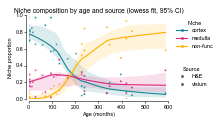

In [40]:
from matplotlib.lines import Line2D

METHOD   = 'logistic'   # 'spline' | 'lowess' | 'logistic'
LOG_X    = False       # log age axis (the fit uses the same scale)
X_OFFSET = 1.0        # months added before logging, so age == 0 is plottable

hue_order = ['cortex', 'medulla', 'non-func']
palette = dict(zip(hue_order, [thyAgeing_colors[c] for c in ['teal', 'magenta', 'yellow']]))
markers = {'H&E': 'o', 'visium': 'X'}

if LOG_X:
    log_x = 'log'
else:
    log_x = 'linear'

fig, ax = plt.subplots(figsize=calc_figsize(width=70, height=40))

lo_age, hi_age = full_df['age_months'].min(), full_df['age_months'].max()
xs_plot = (log_age_grid(lo_age, hi_age, 300, X_OFFSET) if LOG_X
           else np.linspace(lo_age, hi_age, 300))

for niche in hue_order:
    dfg = full_df[full_df['niche_simple'] == niche].dropna(subset=['age_months', 'mean_prop'])
    if dfg.shape[0] < 5:
        continue
    xs, fit, lo, hi = smooth_fit(
        dfg['age_months'], dfg['mean_prop'], groups=dfg['donor'],
        method=METHOD, log_x=LOG_X, x_offset=X_OFFSET, xs=xs_plot, n_boot=500,
    )
    ax.fill_between(xs, lo, hi, color=palette[niche], alpha=0.15, linewidth=0, zorder=2)
    ax.plot(xs, fit, color=palette[niche], linewidth=1.0, zorder=3)

sns.scatterplot(
    data=full_df, x='age_months', y='mean_prop',
    hue='niche_simple', hue_order=hue_order,
    style='source', markers=markers,
    palette=palette, linewidth=0, s=3, alpha=0.85,
    ax=ax, zorder=4, legend=False,
)

if LOG_X:
    # symlog: linear between 0 and 1 month, log above, so birth (0) still shows
    ax.set_xscale('symlog', linthresh=1, linscale=0.4)
    ticks = [0] + [t for t in [3, 6, 12, 24, 60, 120, 240, 480, 720]
                   if lo_age <= t <= hi_age]
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(t) for t in ticks])
    ax.set_xlim(max(lo_age - 0.2, -0.2), hi_age * 1.05)
    ax.minorticks_off()

ax.set_ylim(0, 1)
ax.set_xlabel('Age (months)')
ax.set_ylabel('Niche proportion')
ax.set_title(f'Niche composition by age and source ({METHOD} fit, 95% CI)')

niche_h = [Line2D([], [], color=palette[n], marker='o', linestyle='-', markersize=2,
                  linewidth=1.0, label=n) for n in hue_order]
src_h = [Line2D([], [], color='0.35', marker=m, linestyle='none', markersize=2, label=s)
         for s, m in markers.items()]
leg1 = ax.legend(handles=niche_h, title='Niche', loc='upper left',
                 bbox_to_anchor=(1.02, 1.0), fontsize=5, title_fontsize=5, frameon=False)
ax.add_artist(leg1)
ax.legend(handles=src_h, title='Source', loc='upper left',
          bbox_to_anchor=(1.02, 0.45), fontsize=5, title_fontsize=5, frameon=False)

sns.despine(offset=2, trim=True)
plt.tight_layout()
plt.savefig(f'{plots_path}/morpho_niches2/plotting/thyAgeing_compartmentQuant_wVisium_{METHOD}_{log_x}.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:

plot_grouped_boxplot(data = df, x = col_niche, y = 'mean_prop', hue = 'age_group', order = col_niche_levels, hue_order = ['infant', 'paed', 'adult'], 
                    palette = get_tint_palette(thyAgeing_colors['magenta'], min_tint = 0.3, n = 3), annotator_args = dict(line_offset = 1, text_offset = -3.5, line_offset_to_group = 0.03),
                     x_label = 'Niche', y_label = 'Frequency', legend_title = 'Age group', add_stats = True, format_percent = True, figsize = calc_figsize(height = 60, width = len(col_niche_levels)*5+20),
                     save_stats = f'{data_path}/morpho_niches/thyAgeing_{col_niche}_proportions_boxplot_')
plt.savefig(f'{plots_path}/morpho_niches2/discovery/thyAgeing_{col_niche}_proportions_boxplot.pdf', bbox_inches='tight', dpi=300)